# Saliency explainability

**Question.** Does C0 look at different places when it is wrong? The C0 Grad-CAMs are turned into
**per-organ numbers**, and C0's right and wrong calls are compared on them, per side of its call.
The groups of the image C2 model (its CNN embedding) are then described with the same numbers, and
case cards show real examples.

**Two maps per image, named after C0's call on that image.** `c0_final_predictions.py` stores each
Grad-CAM as two (7, 7) maps scaled to [0, 1]: evidence for the disease and evidence against it.

* **support for the prediction**: the map behind C0's call (for-disease if it said positive,
  against-disease if it said negative)
* **against the prediction**: the other map

The counterfactual (the nearest real image of the other class, `knn_correct_cf`) is always called
the other class, so its maps are named after *its* call.

**Focus, per organ region.** Each map is upsampled to 224 as the CNN reads it and measured inside
the image's own PSPNet organ masks (`code/c1_region_masks.py`, `code/c2_saliency_attributes.py`):

    focus = share of the map inside the region / the region's share of the image area

1 = what an evenly spread map would give the region, > 1 = C0 concentrates its evidence there. Focus
is analysed as log10 (below 0.01 counted as 0.01) and, in the figures, in **SD units within the side
of C0's call** (0 = an average call). Regions overlap as the C1 organs do (the heart shadow counts for
the heart, the left lung and the mediastinum); `Outside` is the part of the image in no organ mask,
drawn on a grey band as the contrast to the anatomy.

**Steps**
1. The CNN to explain and its out-of-fold scores.
2. Focus of the four maps (X-ray / counterfactual × support / against), all five folds.
3. Overview: where wrong calls differ from right ones, every region and map.
4. Key regions per side: the most correlated with correctness, non-redundant.
5. Support for the prediction in the key regions, right vs wrong calls.
6. Groups in the CNN embedding (fold 4), described by their support profile (image and
   counterfactual); 6a average maps; 6b the groups in the CNN ablation's
   embeddings.
7. Case cards: real examples.

**What to expect** (cardiomegaly, effusion): wrong calls take less of their support from the
region where the disease shows (heart region, lung bases) and more from outside the body; the
counterfactual's maps barely differ. Everything describes group averages: single right and wrong
calls overlap a lot. Figures follow `code/thesis_style.py`; `SAVE_FIGS = True` writes them to
`figures/xai/<disease>/` with `saliency_` in the name.

In [ ]:
import os, sys, gc, textwrap, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, torchxrayvision as xrv
from PIL import Image
from matplotlib.colors import to_rgba
from matplotlib.patches import Patch
from tqdm.auto import tqdm

sys.path.insert(0, os.path.abspath("code"))
from c2_msp import msp_score

# effusion | atelectasis | cardiomegaly | consolidation | edema. XAI_DISEASE overrides it, as in the
# attribute notebook.
DISEASE  = os.environ.get("XAI_DISEASE", "cardiomegaly")
SOURCE   = "knn_correct_cf"
K_VALUES = [10]             # the embeddings are written per K by c2_embed_images.py
POLICY   = "ignore"         # C0 uncertainty policy: picks C0_final/multilabel_<policy>
print(DISEASE, SOURCE, K_VALUES)

RESULTS   = os.environ.get("THESIS_RESULTS", "/work3/s251710/thesis_results")
DATA_ROOT = os.environ.get("THESIS_DATA", "/work3/s251710/thesis_data")
C2        = os.path.join(RESULTS, "C2_final_results")
C0_DIR    = os.path.join(RESULTS, "C0_final", f"multilabel_{POLICY}", DISEASE)

import importlib, thesis_style
importlib.reload(thesis_style)     # pick up edits to the style file without a kernel restart
from thesis_style import *
apply()

SAVE_FIGS   = True
RUN_ALL_SPACES = True   # step 6b: also cluster + t-SNE the embeddings of the CNN ablation (xi,
                         # xi_sal, dual) and draw the four-spaces figure (slow). Off: only the
                         # explained model's map the case cards need (panel d) is computed.
FIG_DIR     = os.path.join("figures", "xai", DISEASE)
FIG_FORMATS = ("pdf", "png")

def fig_path(name, ext):
    return os.path.join(FIG_DIR, f"{DISEASE}_{SOURCE}_saliency_{name}.{ext}")

def save(fig, name):
    """Write `fig` as FIG_DIR/<disease>_<source>_saliency_<name>.{pdf,png}."""
    if SAVE_FIGS:
        os.makedirs(FIG_DIR, exist_ok=True)
        for ext in FIG_FORMATS:
            fig.savefig(fig_path(name, ext))

def save_text(name, text):
    """Write a figure's caption / details beside it, as .txt."""
    if SAVE_FIGS:
        os.makedirs(FIG_DIR, exist_ok=True)
        with open(fig_path(name, "txt"), "w", encoding="utf-8") as f:
            f.write(text.rstrip() + "\n")

cardiomegaly knn_correct_cf [10]


## 1. The CNN to explain

The best image model by mean AUROC is explained (set `MODEL` to force one). `dual_sal_scalars` is
excluded: its head reads C0's probability, so its groups could simply be bins of it. Its
**out-of-fold** scores (one per query, pooled over the five folds) are the quality score used in
every step; the embedding of step 6 is fold 4 only.

In [18]:
MODEL   = None                   # None = best by AUROC; or a key such as "dual_sal", "xi_sal"
EXCLUDE = {"dual_sal_scalars"}   # its head takes C0's probability

summaries = pd.concat([pd.read_csv(os.path.join(C2, DISEASE, SOURCE, f"cf_{k}", "images",
                                                "cv_summary.csv")).assign(K=k) for k in K_VALUES])
summaries = (summaries[~summaries["model"].isin(EXCLUDE)]
             .sort_values("auc_mean", ascending=False, ignore_index=True))
display(summaries[["K", "model", "name", "auc_mean", "auc_std"]])
best = summaries.iloc[0] if MODEL is None else summaries[summaries["model"] == MODEL].iloc[0]
BEST_K, BEST_MODEL = int(best["K"]), best["model"]
print(f"explaining: {best['name']} ({BEST_MODEL}) at K={BEST_K}  "
      f"(AUROC {best['auc_mean']:.4f} ± {best['auc_std']:.4f})")

# Out-of-fold predictions of that model: one row per query, pooled over the 5 folds.
k_dir = os.path.join(C2, DISEASE, SOURCE, f"cf_{BEST_K}")
model_scores = pd.concat(
    [pd.read_csv(os.path.join(k_dir, "images", BEST_MODEL, f"fold_{i}_predictions.csv"))
     for i in range(5)], ignore_index=True)
model_scores = model_scores.rename(columns={f"{BEST_MODEL}_prob": "model_score"})

,K,model,name,auc_mean,auc_std
0,10,dual_sal,Dual Encoder + Saliency,0.916261,0.002622
1,10,dual,Dual Encoder,0.908429,0.002182
2,10,xi_sal,CNN Xi + Saliency,0.902640,0.003089
3,10,cf_sal,CNN CF + Saliency,0.878298,0.003807
4,10,cf,CNN CF,0.876091,0.003147
5,10,xi,CNN Xi,0.862369,0.002073


explaining: Dual Encoder + Saliency (dual_sal) at K=10  (AUROC 0.9163 ± 0.0026)


## 2. Focus of the four maps

`saliency_attributes.csv` holds every query of the five test folds and its **nearest**
counterfactual, in the fixed directions C0 stores. This cell orients both maps by each image's own
call and keeps the log10 focus of the 14 regions in four forms:

* `<region>_focus`: X-ray, support for the prediction
* `opp_<region>_focus`: X-ray, against the prediction
* `cf_<region>_focus`: counterfactual, support for its own call
* `cf_opp_<region>_focus`: counterfactual, against its own call

The orientation uses C0's stored `pred` (the call `correct` is defined on). Build the CSV with
`jobs/c1_region_masks.sh` (once, all diseases) and `jobs/c2_saliency_attributes.sh`.

In [19]:
sal_file = os.path.join(C2, DISEASE, SOURCE, "saliency_attributes.csv")
assert os.path.exists(sal_file), (f"missing {sal_file}: bsub -env \"all, DISEASES={DISEASE}\" "
                                  f"< jobs/c2_saliency_attributes.sh  (after jobs/c1_region_masks.sh)")
sal = pd.read_csv(sal_file)
RAW_ATTRS = [c for c in sal.columns if c not in ("path", "cf_path", "fold")
             and not c.startswith(("cf_attr_", "delta_"))]

# C0's call per image (the attribute notebook's column names), and C0's call / probability for the CF
c0 = pd.read_csv(os.path.join(C0_DIR, f"C2_dataset_c0_{DISEASE}.csv"),
                 usecols=["path", "prob", "true", "pred"])
data = (sal.merge(model_scores[["path", "patient_id", "correct", "model_score"]], on="path",
                  how="left", validate="one_to_one")
           .merge(c0.rename(columns={"prob": f"{DISEASE}_prob", "true": f"{DISEASE}_true",
                                     "pred": f"{DISEASE}_pred"}),
                  on="path", how="left", validate="one_to_one"))
assert data[["model_score", f"{DISEASE}_pred"]].notna().all().all(), "some queries have no score or C0 row"
assert (data["correct"] == (data[f"{DISEASE}_pred"] == data[f"{DISEASE}_true"])).all(), \
    "CNN's `correct` disagrees with C0's call"
data["correct"] = data["correct"].astype(int)
data["cf_prob"] = data["cf_path"].map(dict(zip(c0["path"], c0["prob"])))   # a KNN CF is a C2 image
data["cf_pred"] = data["cf_path"].map(dict(zip(c0["path"], c0["pred"])))
assert data["cf_pred"].notna().all(), "some counterfactuals have no C0 call"
del sal

# ── Orient by each image's own call: sup = the map supporting it, opp = the one opposing it ──
def renamed(c, new):
    """'Heart_pos_share' -> 'Heart_<new>_share', 'Lung asymmetry_pos' -> 'Lung asymmetry_<new>'."""
    return c.replace("_pos_", f"_{new}_") if "_pos_" in c else c[:-len("pos")] + new

POS_COLS = [c for c in RAW_ATTRS if "_pos_" in c or c.endswith("_pos")]
assert set(RAW_ATTRS) == set(POS_COLS) | {renamed(c, "neg") for c in POS_COLS} | {"CAM_balance"}, \
    "unexpected saliency columns"

def oriented(prefix, positive):
    """The sup / opp block of one form ('' = image, 'cf_attr_' = CF), oriented by `positive`."""
    out = {}
    for block, own, other in [("sup", "pos", "neg"), ("opp", "neg", "pos")]:
        for c in POS_COLS:
            a, b = prefix + renamed(c, own), prefix + renamed(c, other)
            out[renamed(c, block)] = np.where(positive, data[a], data[b])
    out["CAM_sup_balance"] = np.where(positive, 1, -1) * data[prefix + "CAM_balance"]
    return pd.DataFrame(out, index=data.index)

img = oriented("", data[f"{DISEASE}_pred"].values == 1)
cf  = oriented("cf_attr_", data["cf_pred"].values == 1)
pred_ = data[f"{DISEASE}_pred"].astype(int)
for block, name in [("sup", "supporting"), ("opp", "opposing")]:
    print(f"empty {name} map (scale 0):  "
          + "  ".join(f"{n} {(img.loc[pred_ == p, f'CAM_{block}_scale'] <= 0).mean():.1%}"
                      for p, n in [(1, "positive calls"), (0, "negative calls")])
          + f"  |  their CFs {(cf[f'CAM_{block}_scale'] <= 0).mean():.1%}")

# Focus (enrichment = share / area) of both maps of both images, as log10: focus 1 = 0. Below
# 1% of an even spread counts as 0.01 (log 0 is undefined).
EPS_FOCUS = 0.01
REGIONS   = [c[:-len("_sup_enrichment")] for c in img.columns if c.endswith("_sup_enrichment")]

def log_focus(frame, block):
    out = np.log10(frame[[f"{r}_{block}_enrichment" for r in REGIONS]].clip(lower=EPS_FOCUS))
    return out.set_axis([f"{r}_focus" for r in REGIONS], axis=1)

ATTR_COLS   = [f"{r}_focus" for r in REGIONS]          # image: evidence for its call
OPP_COLS    = [f"opp_{a}" for a in ATTR_COLS]           # image: evidence against its call
CF_COLS     = [f"cf_{a}" for a in ATTR_COLS]            # CF: evidence for its call
CF_OPP_COLS = [f"cf_opp_{a}" for a in ATTR_COLS]        # CF: evidence against its call
raw = RAW_ATTRS + [f"{f}{c}" for f in ("cf_attr_", "delta_") for c in RAW_ATTRS]
data = pd.concat([data.drop(columns=raw),
                  log_focus(img, "sup"), log_focus(img, "opp").add_prefix("opp_"),
                  log_focus(cf, "sup").add_prefix("cf_"), log_focus(cf, "opp").add_prefix("cf_opp_")],
                 axis=1)
del img, cf

print(f"{len(data):,} images | {len(ATTR_COLS)} regions x (image, CF) x (for, against) "
      f"| error rate {1 - data['correct'].mean():.3f} | CF probability found for "
      f"{data['cf_prob'].notna().mean():.1%} | CF called the other class: "
      f"{(data['cf_pred'] != pred_).mean():.1%}")

empty supporting map (scale 0):  positive calls 0.1%  negative calls 0.0%  |  their CFs 0.0%
empty opposing map (scale 0):  positive calls 0.0%  negative calls 76.4%  |  their CFs 16.6%
92,507 images | 14 regions x (image, CF) x (for, against) | error rate 0.190 | CF probability found for 100.0% | CF called the other class: 100.0%


## 4. Key regions per side

Per side of C0's call, the regions are ranked by the correlation of the X-ray's **support** focus
with correctness (all calls of that side, all five folds). Greedy selection keeps a region only if
its |correlation| with every region already kept is below `MAX_REDUNDANCY`; whole lungs are left out
because their upper and lower halves are finer versions of them (r 0.85-0.94 between a lung and its
lower half). The disease's **anchor region** (the heart for cardiomegaly, the diaphragm for
effusion) is always kept first, so every figure and card shows the organ the disease is about; the
ranking fills the remaining slots up to `N_KEEP`, plus `Outside` as the contrast. These are the
regions every later figure and case card draws for that side. The ranking is computed once on labelled data, so a new image
only needs its focus on these fixed regions.

The cell after the selection writes the full ranking as a table (`saliency_region_correlations.csv`, Table 9b of TABLES.ipynb): per region the correlation of every map with correctness, and how much of it is left once MSP is known.

In [20]:
from matplotlib.transforms import blended_transform_factory, offset_copy

pred      = data[f"{DISEASE}_pred"].astype(int)
SIDES     = {1: "C0 says positive (TP vs FP)", 0: "C0 says negative (TN vs FN)"}
SIDE_NAME = {1: "Positive predictions", 0: "Negative predictions"}
REGION_NAMES = [a[:-len("_focus")] for a in ATTR_COLS]
FORM_COLS = {"X-ray · support": "", "X-ray · against": "opp_",
             "Counterfactual · support": "cf_", "Counterfactual · against": "cf_opp_"}
TOP_N   = 5       # regions shown per side (the CSV keeps all of them)
HDR     = 24      # points above the cells for the X-ray / Counterfactual bracket; raise it if it touches the column labels
SMALL_D = 0.2     # |d| at or above this is printed in bold


In [21]:
N_KEEP, MAX_REDUNDANCY = 4, 0.6
CANDIDATES = [r for r in REGION_NAMES if r not in ("Left Lung", "Right Lung", "Outside")]
ANCHOR = {}.get(DISEASE, [])                    # no anchor: regions chosen by the data only, as in the attribute arm

SEL = {}                                        # side -> regions drawn (key regions + Outside)
for p, title in SIDES.items():
    rows = pred == p
    ok   = data.loc[rows, "correct"].astype(float)
    Xs   = data.loc[rows, [f"{r}_focus"     for r in CANDIDATES]].set_axis(CANDIDATES, axis=1)  # support
    Xa   = data.loc[rows, [f"opp_{r}_focus" for r in CANDIDATES]].set_axis(CANDIDATES, axis=1)  # against
    r_ok = pd.concat([Xs.corrwith(ok).abs(), Xa.corrwith(ok).abs()], axis=1).max(axis=1)        # strongest of the two maps
    r_ok = r_ok.sort_values(ascending=False)
    kept = [a for a in ANCHOR if a in CANDIDATES]
    for r in r_ok.index:
        if r in kept:
            continue
        if all(abs(Xs[r].corr(Xs[k])) < MAX_REDUNDANCY for k in kept):
            kept.append(r)
        if len(kept) == N_KEEP:
            break
    SEL[p] = kept + ["Outside"]
    print(title)

C0 says positive (TP vs FP)
C0 says negative (TN vs FN)


In [ ]:
# The step-4 ranking as a table, the saliency twin of the attribute notebook's top-attribute table.
# Saved for TABLES.ipynb as FIG_DIR/<disease>_<source>_saliency_region_correlations.csv. Per side
# and region (log focus):
#   rank        place in the step-4 ranking of CANDIDATES by |r_best|; empty for the unranked
#               regions (whole lungs, Outside)
#   selected    order in SEL: 1..N_KEEP the key regions, then Outside; else empty
#   r_<form>    r with correctness of the X-ray's support / against map and the CF's
#   best form   the stronger of the X-ray's two maps, the one step 4 ranks by
#   d_<form>    mean(correct) - mean(wrong) in SD units of the side (same sign as r)
#   r_msp       r of the best form with threshold MSP: does the focus just track C0's confidence?
#   r_given_msp partial r of the best form with correctness, MSP held fixed
FORMS  = {"support": "", "against": "opp_", "CF support": "cf_", "CF against": "cf_opp_"}
RANKED = ["support", "against"]                 # the forms step 4 ranks by
c0_t   = float(open(os.path.join(C0_DIR, "threshold.txt")).read())

def partial_r(r_xy, r_xz, r_yz):
    return (r_xy - r_xz * r_yz) / np.sqrt((1 - r_xz ** 2) * (1 - r_yz ** 2))

region_corr = []
for p in SIDES:
    d     = data[pred == p]
    ok    = d["correct"].astype(bool)
    msp_p = pd.Series(msp_score(d[f"{DISEASE}_prob"].values, c0_t, "threshold"), index=d.index)
    r_ok_msp = np.corrcoef(d["correct"], msp_p)[0, 1]
    t = pd.DataFrame({"region": REGION_NAMES})
    for form, pre in FORMS.items():
        X = d[[f"{pre}{r}_focus" for r in REGION_NAMES]]
        t[f"r_{form}"] = X.corrwith(d["correct"]).fillna(0).values
        t[f"d_{form}"] = ((X[ok].mean() - X[~ok].mean()) / X.std().replace(0, np.nan)).fillna(0).values
    r = t[[f"r_{f}" for f in RANKED]].to_numpy()
    best_form = np.abs(r).argmax(axis=1)            # not `best`: that is the explained model (step 1)
    t["best form"] = np.array(RANKED)[best_form]
    t["r_best"]    = r[np.arange(len(t)), best_form]
    ranked = t[t["region"].isin(CANDIDATES)].sort_values("r_best", key=abs, ascending=False)["region"]
    t.insert(0, "side", p)
    t.insert(1, "rank", t["region"].map({a: i + 1 for i, a in enumerate(ranked)}).astype("Int64"))
    t.insert(2, "selected", t["region"].map({a: i + 1 for i, a in enumerate(SEL[p])}).astype("Int64"))
    key = t.set_index("region").loc[SEL[p][:-1], "rank"]
    assert key.is_monotonic_increasing, f"ranking differs from step 4's selection: {key.to_dict()}"
    best_cols = [f"{FORMS[f]}{a}_focus" for f, a in zip(t["best form"], t["region"])]
    t["r_msp"]       = d[best_cols].corrwith(msp_p).fillna(0).values
    t["r_given_msp"] = partial_r(t["r_best"], t["r_msp"], r_ok_msp)
    t["n_calls"], t["error_rate"], t["r_msp_correct"] = len(d), 1 - ok.mean(), r_ok_msp
    region_corr.append(t.sort_values("rank", na_position="last"))

region_corr = pd.concat(region_corr, ignore_index=True).assign(disease=DISEASE, source=SOURCE)
os.makedirs(FIG_DIR, exist_ok=True)
region_corr.to_csv(fig_path("region_correlations", "csv"), index=False)
print(f"wrote {fig_path('region_correlations', 'csv')} ({len(region_corr):,} rows)")
for p, title in SIDES.items():
    t = region_corr[(region_corr["side"] == p) & region_corr["selected"].notna()].sort_values("selected")
    print(f"{title}: {t['n_calls'].iloc[0]:,} calls, error rate {t['error_rate'].iloc[0]:.3f}")
    display(t.set_index("region")[["rank", *[f"r_{f}" for f in FORMS], "best form", "r_msp",
                                   "r_given_msp"]].round(3))

## 3. Overview: where wrong calls differ from right ones

One cell per region and map: **Cohen's d of wrong minus right calls** (difference of the means of
log focus, divided by the side's SD). Red = wrong calls concentrate more of that evidence in the
region, blue = less. Sorted by each region's strongest cell. The table is saved as
`<disease>_<source>_saliency_effect_sizes.csv` for TABLES.ipynb.

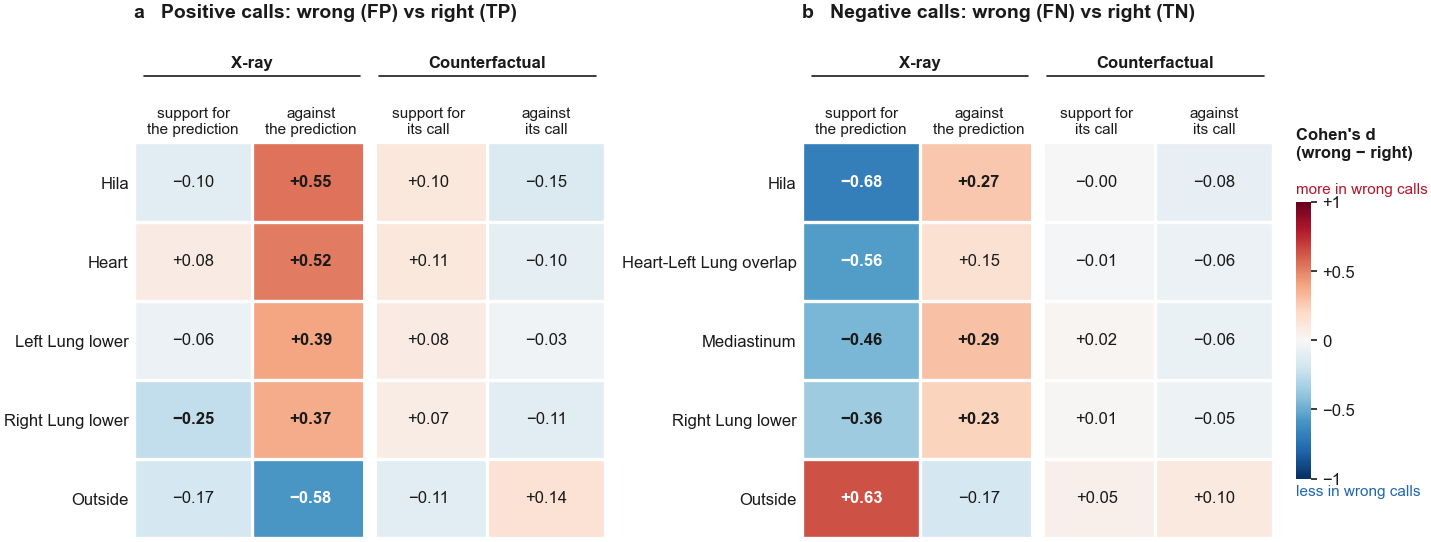

In [22]:
from matplotlib.transforms import blended_transform_factory, offset_copy

pred      = data[f"{DISEASE}_pred"].astype(int)
SIDES     = {1: "C0 says positive (TP vs FP)", 0: "C0 says negative (TN vs FN)"}
SIDE_NAME = {1: "Positive predictions", 0: "Negative predictions"}
REGION_NAMES = [a[:-len("_focus")] for a in ATTR_COLS]
FORM_COLS = {"X-ray · support": "", "X-ray · against": "opp_",
             "Counterfactual · support": "cf_", "Counterfactual · against": "cf_opp_"}
TOP_N   = 5       # regions shown per side (the CSV keeps all of them)
HDR     = 24      # points above the cells for the X-ray / Counterfactual bracket; raise it if it touches the column labels
SMALL_D = 0.2     # |d| at or above this is printed in bold

def cohen_d(rows, col):
    """Wrong minus right calls among `rows`, in SD units of `col`."""
    x, ok = data.loc[rows, col], data.loc[rows, "correct"].astype(bool)
    return (x[~ok].mean() - x[ok].mean()) / x.std()

EFFECT = pd.concat({p: pd.DataFrame({form: [cohen_d(pred == p, f"{pre}{r}_focus") for r in REGION_NAMES]
                                     for form, pre in FORM_COLS.items()}, index=REGION_NAMES)
                    for p in SIDES}, names=["side", "region"])
os.makedirs(FIG_DIR, exist_ok=True)
EFFECT.to_csv(fig_path("effect_sizes", "csv"))

LABEL = lambda r: r.replace("Facies Diaphragmatica", "Diaphragm")
fmt   = lambda v: f"{v:+.2f}".replace("-", "−")
COLS  = ["support for\nthe prediction", "against\nthe prediction", "support for\nits call", "against\nits call"]

fig, axes = plt.subplots(1, 2, figsize=(FULL, (30 + 8 * TOP_N) * MM), layout="constrained")
for ax, (p, title) in zip(axes, [(1, "a   Positive predictions: wrong (FP) vs right (TP)"),
                                 (0, "b   Negative predictions: wrong (FN) vs right (TN)")]):
    d = EFFECT.loc[p]
    d = d.loc[SEL[p]]  
    im = ax.imshow(d.values, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")

    # cell numbers: dark ink everywhere, bold when |d| >= SMALL_D
    for (i, j), v in np.ndenumerate(d.values):
        ax.text(j, i, fmt(v), ha="center", va="center", fontsize=FS["small"],
                color="white" if abs(v) > 0.55 else INK,
                fontweight="bold" if abs(v) >= SMALL_D else "normal")

    # white cell grid + wider gap between X-ray and Counterfactual
    ax.set_xticks(np.arange(-0.5, 4), minor=True)
    ax.set_yticks(np.arange(-0.5, len(d)), minor=True)
    ax.grid(which="major", visible=False)
    ax.grid(which="minor", color="white", lw=1.2)
    ax.axvline(1.5, color="white", lw=5)

    # column + row labels
    ax.set_xticks(range(4), COLS, fontsize=FS["tiny"])
    ax.set_yticks(range(len(d)), [LABEL(r) for r in d.index])
    ax.tick_params(which="both", length=0)
    ax.xaxis.set_ticks_position("top")

    # group bracket: fixed distance (points) above the cells, independent of row height
    base   = blended_transform_factory(ax.transData, ax.transAxes)
    t_line = offset_copy(base, fig=fig, y=HDR, units="points")
    t_text = offset_copy(base, fig=fig, y=HDR + 2, units="points")
    for x, g in [(0.5, "X-ray"), (2.5, "Counterfactual")]:
        ax.plot([x - 0.92, x + 0.92], [1, 1], transform=t_line, color=INK, lw=0.6, clip_on=False)
        ax.text(x, 1, g, transform=t_text, ha="center", va="bottom",
                fontsize=FS["small"], fontweight="bold")
    ax.set_xlim(-0.5, 3.5)
    ax.set_ylim(len(d) - 0.5, -0.5)

    ax.set_title(title, loc="left", pad=45, fontsize=FS["base"], fontweight="bold")
    ax.spines[:].set_visible(False)

cb = fig.colorbar(im, ax=axes, shrink=0.7, aspect=18, pad=0.02, ticks=[-1, -0.5, 0, 0.5, 1])
cb.ax.set_yticklabels(["−1", "−0.5", "0", "+0.5", "+1"])
cb.ax.tick_params(labelsize=FS["small"], length=2)
cb.outline.set_visible(False)
cb.ax.set_title("Cohen's d\n(wrong − right)", fontsize=FS["small"], loc="left", pad=16)
cb.ax.text(0, 1.02, "more in wrong predictions", transform=cb.ax.transAxes, ha="left", va="bottom",
           fontsize=FS["tiny"], color="#B2182B")
cb.ax.text(0, -0.02, "less in wrong predictions", transform=cb.ax.transAxes, ha="left", va="top",
           fontsize=FS["tiny"], color="#2166AC")
save(fig, "effect_heatmap")
plt.show()

## 5. Support for the prediction, right vs wrong calls

One square panel per side of C0's call, the side's key regions and `Outside` (grey band). Each
region is a vertical dumbbell: **filled = right calls, hollow = wrong calls**, at their mean support
focus in SD units of the side (0 = an average call); the line length is the d printed above it.
A hollow dot below the filled one means wrong calls take less of their support from that region.
The other three maps of the overview are not drawn; their largest |d| is printed under the figure.

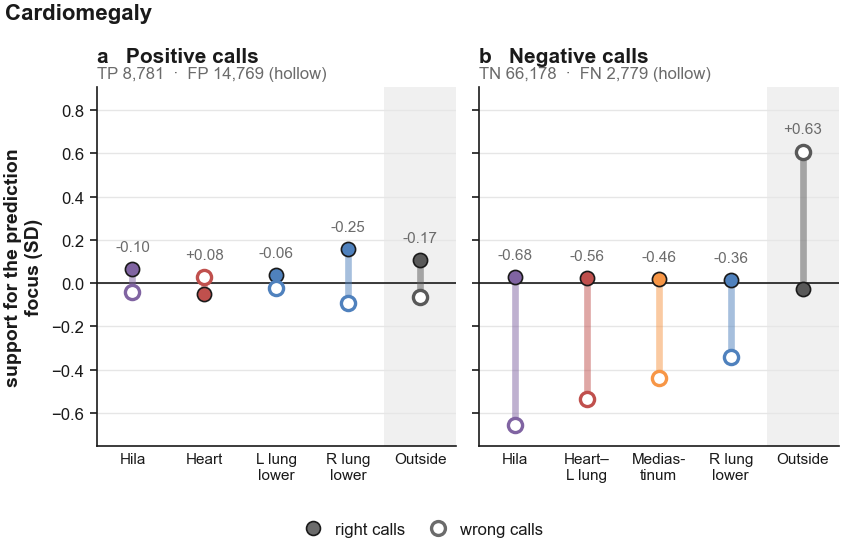

Positive calls: on these regions, the other maps differ by |d| ≤ 0.58 (X-ray · against), 0.11 (Counterfactual · support), 0.15 (Counterfactual · against)
Negative calls: on these regions, the other maps differ by |d| ≤ 0.29 (X-ray · against), 0.05 (Counterfactual · support), 0.10 (Counterfactual · against)


In [23]:
true = data[f"{DISEASE}_true"].astype(int)
quadrant = np.select([(pred == 1) & (true == 1), (pred == 1) & (true == 0),
                      (pred == 0) & (true == 0)], ["TP", "FP", "TN"], "FN")
ROWS = {1: ["TP", "FP"], 0: ["TN", "FN"]}

# Colours: one per anatomical group, first match wins (also for the raw PSPNet structures outlined
# on the case cards).
ORGAN_GROUPS = {
    "heart":       (["Heart"],                                 "#C0504D"),
    "lungs":       (["Left Lung", "Right Lung"],               "#4F81BD"),
    "hila":        (["Hila", "Hilus"],                         "#8064A2"),
    "mediastinum": (["Mediastinum", "Aorta", "Weasand"],       "#F79646"),
    "skeletal":    (["Bones", "Scapula", "Clavicle", "Spine"], "#9BBB59"),
    "diaphragm":   (["Facies Diaphragmatica"],                 "#4BACC6"),
    "outside":     (["Outside"],                               "#595959"),
}
def organ_group(f):
    return next((g for g, (keys, _) in ORGAN_GROUPS.items() if any(k in f for k in keys)), "other")
def organ_color(f):
    g = organ_group(f)
    return ORGAN_GROUPS[g][1] if g != "other" else "#A6A6A6"

DB         = {"line": 2.4, "dot": 26, "edge": 0.6, "hollow": 1.2}   # the attribute notebook's sizes
SQUARE     = 34 * MM
OUTSIDE_BG = dict(color="#000000", alpha=0.06, lw=0, zorder=0)
SHORT      = {"Facies Diaphragmatica": "Diaphr.", "Heart-Left Lung overlap": "Heart–\nL lung",
              "Mediastinum": "Medias-\ntinum", **{f"{s} Lung {h}": f"{s[0]} lung\n{h}"
                                                for s in ("Left", "Right") for h in ("upper", "lower")}}

def tighten(fig):
    fig.get_layout_engine().set(w_pad=1 * MM, h_pad=1 * MM, wspace=0.02, hspace=0.04)

def zframe(prefix):
    """Log focus of one form in SD units within the side of C0's call (0 = an average call)."""
    out = pd.DataFrame(index=data.index, columns=REGION_NAMES, dtype=float)
    for p in SIDES:
        rows = pred == p
        X = data.loc[rows, [f"{prefix}{r}_focus" for r in REGION_NAMES]].set_axis(REGION_NAMES, axis=1)
        out.loc[rows] = ((X - X.mean()) / X.std()).values
    return out

ZS, ZOPP = zframe(""), zframe("opp_")    # X-ray support for its call, X-ray evidence against it

def vdumbbells(ax, regions, filled, hollow, labels=None):
    """One vertical dumbbell per region: filled and hollow dot at their values; Outside on grey."""
    if "Outside" in regions:
        i = regions.index("Outside")
        ax.axvspan(i - 0.5, i + 0.5, **OUTSIDE_BG)
    for xi, r in enumerate(regions):
        a, b, c = filled[r], hollow[r], organ_color(r)
        ax.plot([xi, xi], [a, b], color=c, lw=DB["line"], alpha=0.5, solid_capstyle="butt", zorder=2)
        ax.scatter([xi], [a], s=DB["dot"], color=c, edgecolor=INK, lw=DB["edge"], zorder=3)
        ax.scatter([xi], [b], s=DB["dot"], facecolor="white", edgecolor=c, lw=DB["hollow"], zorder=3)
        if labels is not None:
            ax.text(xi, max(a, b) + 0.07, labels[r], ha="center", va="bottom",
                    fontsize=FS["tiny"], color=MUTED)
    ax.set_xticks(range(len(regions)), [SHORT.get(r, r) for r in regions], fontsize=FS["tiny"])
    ax.tick_params(axis="x", length=0)
    ax.axhline(0, color=INK, lw=LW["axis"], zorder=1)
    ax.grid(axis="y"); ax.set_axisbelow(True)
    ax.set_xlim(-0.5, len(regions) - 0.5)
    ax.set_box_aspect(1)

def dot_legend(fig, labels):
    fig.legend(handles=[plt.Line2D([], [], marker="o", ls="", ms=5, color=MUTED, markeredgecolor=INK,
                                   markeredgewidth=DB["edge"]),
                        plt.Line2D([], [], marker="o", ls="", ms=5, markerfacecolor="white",
                                   markeredgecolor=MUTED, markeredgewidth=DB["hollow"])],
               labels=labels, loc="outside lower center", ncol=2)

fig, axes = plt.subplots(1, 2, figsize=(2 * SQUARE + 40 * MM, SQUARE + 36 * MM), sharey=True,
                         layout="constrained")
tighten(fig)
values = []
for ax, letter, (p, (q_ok, q_bad)) in zip(axes, "ab", ROWS.items()):
    rows = pred == p
    ok   = data.loc[rows, "correct"].astype(bool).values
    Z    = ZS.loc[rows, SEL[p]]
    right, wrong = Z[ok].mean(), Z[~ok].mean()
    values += list(right) + list(wrong)
    vdumbbells(ax, SEL[p], right, wrong,
               labels={r: f"{EFFECT.loc[p].loc[r, 'X-ray · support']:+.2f}" for r in SEL[p]})
    ax.set_title(f"{letter}   {SIDE_NAME[p]}", loc="left", pad=9)
    ax.text(0, 1.015, f"{q_ok} {ok.sum():,}  ·  {q_bad} {(~ok).sum():,} (hollow)", transform=ax.transAxes,
            fontsize=FS["small"], color=MUTED, va="bottom")
axes[0].set_ylim(min(values) - 0.1, max(values) + 0.3)
axes[0].set_ylabel("support for the prediction\nfocus (SD)", fontweight="bold")
fig.suptitle(DISEASE.capitalize(), x=0.01, ha="left")
dot_legend(fig, ["right predictions", "wrong predictions"])
save(fig, "support_right_wrong")
plt.show()

for p in SIDES:
    others = EFFECT.loc[p].loc[SEL[p], ["X-ray · against", "Counterfactual · support",
                                        "Counterfactual · against"]].abs().max()
    print(f"{SIDE_NAME[p]}: on these regions, the other maps differ by |d| ≤ "
          + ", ".join(f"{v:.2f} ({k})" for k, v in others.items()))

## 6. Groups in the CNN embedding, described by their support profile

The CNN maps every image into a space organised by correctness: the input of its output layer,
written by `code/c2_embed_images.py` (`jobs/c2_embed_images.sh`, fold 4 only, since the five fold
models do not share a space). Per side of C0's call the fold-4 images are clustered with k-means
(fit on one patient half, the other only assigned), and the groups are named **A, B, C** by error
rate, A the lowest. The table checks each group: error rate (also on the held-out half), mean C2
percentile, mean MSP, and C2 / MSP AUROC inside the group.

In [24]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupShuffleSplit
from c2_msp import msp_score

EMB_FOLD   = 4         # the fold the CNN was NOT trained on (c2_embed_images.py --fold)
N_CLUSTERS = 3

# C0 confidence per image: threshold MSP, from C0's probability and its Youden threshold.
c0_t = float(open(os.path.join(C0_DIR, "threshold.txt")).read())
msp  = msp_score(data[f"{DISEASE}_prob"].values, c0_t, "threshold")

# C2's quality score as a percentile WITHIN C0's call (0 = least trusted, 1 = most trusted):
# the raw score is class-balanced, not calibrated, so only its rank is meaningful.
data["c2_pct"] = data.groupby(pred)["model_score"].rank(pct=True)

def GROUP(k, n=None):
    """Cluster id -> display name: 'group A' is the lowest error rate, then B, C... (n groups,
    default N_CLUSTERS)."""
    return f"group {'ABCDEFGHIJ'[(n or N_CLUSTERS) - k]}"

def summarise_groups(title, rows, labels, held_out, n):
    """Renumber k-means labels 1..n by error rate on the fitting rows (1 = most errors), show the
    group table and return the group id per row."""
    d = pd.DataFrame({"cluster": labels, "error": 1 - data.loc[rows, "correct"].values,
                      "msp": msp[rows], "c2": data.loc[rows, "c2_pct"].values,
                      "score": data.loc[rows, "model_score"].values, "held_out": held_out})
    order = d[~d.held_out].groupby("cluster")["error"].mean().sort_values(ascending=False).index
    d["cluster"] = d["cluster"].map({c: i + 1 for i, c in enumerate(order)})

    def auroc(x, col):                 # how well a score ranks right vs wrong calls within x
        return roc_auc_score(1 - x["error"], x[col]) if x["error"].nunique() == 2 else np.nan

    g = d.groupby("cluster")
    table = pd.DataFrame({
        "n":                        g.size(),
        "error rate":               g["error"].mean(),
        "error rate (held-out)":    d[d.held_out].groupby("cluster")["error"].mean(),
        "mean C2 percentile":       g["c2"].mean(),
        "mean MSP":                 g["msp"].mean(),
        "C2 AUROC":                 pd.Series({k: auroc(x, "score") for k, x in g}),
        "MSP AUROC":                pd.Series({k: auroc(x, "msp") for k, x in g}),
    })
    print(f"{title}: base error rate {d['error'].mean():.3f}, base mean MSP {d['msp'].mean():.3f}, "
          f"AUROC C2 {auroc(d, 'score'):.3f} / MSP {auroc(d, 'msp'):.3f}")
    table.index = table.index.map(lambda k: GROUP(k, n))
    display(table.sort_index().round(3))
    return pd.Series(d["cluster"].values, index=rows)

emb_file = os.path.join(k_dir, "images_embeddings", BEST_MODEL, f"fold_{EMB_FOLD}.npz")
assert os.path.exists(emb_file), (f"missing {emb_file}: bsub -env \"all, DISEASE={DISEASE}, "
                                  f"CF_COUNT={BEST_K}, MODELS={BEST_MODEL}\" < jobs/c2_embed_images.sh")
f = np.load(emb_file)
emb_rows = pd.Index(pd.Series(data.index, index=data["path"]).loc[f["paths"]].values)
assert (data.loc[emb_rows, "correct"].values == f["correct"]).all(), "rows do not line up"
assert (data.loc[emb_rows, "cf_path"].values == f["cf_path"]).all(), "nearest CF differs"
assert (data.loc[emb_rows, "fold"] == EMB_FOLD).all(), "embedding rows are not fold 4"

H    = f["h"]                                              # nearest CF only
live = H.std(axis=0) > 0                                   # dead ReLU units carry nothing
EMB  = pd.DataFrame(H[:, live], index=emb_rows)
emb_prob = pd.Series(f["prob"], index=emb_rows)
print(f"CNN {BEST_MODEL}: {live.sum()}/{len(live)} live units, "
      f"{len(EMB):,} images of fold {EMB_FOLD} | its slot-0 AUROC "
      f"{roc_auc_score(data.loc[emb_rows, 'correct'], emb_prob):.4f}")

def cluster_space(p, idx):
    """The clustering features of rows `idx`: their embedding (the same space on both sides)."""
    return EMB.loc[idx].values

# Is the embedding close to one-dimensional?
for p, title in SIDES.items():
    rows = emb_rows[(pred.loc[emb_rows] == p).values]
    pca  = PCA().fit(EMB.loc[rows])
    pc1  = pca.transform(EMB.loc[rows])[:, 0]
    print(f"{title}: variance in PC1-3 {np.round(pca.explained_variance_ratio_[:3], 3)} | "
          f"|r(PC1, CNN score)| = {abs(np.corrcoef(pc1, emb_prob.loc[rows])[0, 1]):.3f}")

# Held-out check inside fold 4: k-means fit on one patient-disjoint half, the other only assigned.
fit_half = pd.Series(False, index=emb_rows)
tr, _ = next(GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=42)
             .split(emb_rows, groups=data.loc[emb_rows, "patient_id"]))
fit_half.iloc[tr] = True

cluster = {}                                   # side -> group id per row (1 = most errors)
for p, title in SIDES.items():
    rows   = emb_rows[(pred.loc[emb_rows] == p).values]
    X      = cluster_space(p, rows)
    fit    = fit_half.loc[rows].values
    labels = KMeans(N_CLUSTERS, n_init=10, random_state=42).fit(X[fit]).predict(X)
    cluster[p] = summarise_groups(title, rows, labels, ~fit, N_CLUSTERS)

CNN dual_sal: 85/256 live units, 18,256 images of fold 4 | its slot-0 AUROC 0.9154
C0 says positive (TP vs FP): variance in PC1-3 [0.516 0.277 0.069] | |r(PC1, CNN score)| = 0.899
C0 says negative (TN vs FN): variance in PC1-3 [0.892 0.042 0.018] | |r(PC1, CNN score)| = 0.817
C0 says positive (TP vs FP): base error rate 0.642, base mean MSP 0.441, AUROC C2 0.727 / MSP 0.728


,n,error rate,error rate (held-out),mean C2 percentile,mean MSP,C2 AUROC,MSP AUROC
group A,1346,0.389,0.384,0.812,0.699,0.689,0.697
group B,2486,0.703,0.700,0.311,0.389,0.601,0.605
group C,968,0.837,0.815,0.159,0.217,0.582,0.560


C0 says negative (TN vs FN): base error rate 0.042, base mean MSP 0.958, AUROC C2 0.722 / MSP 0.733


,n,error rate,error rate (held-out),mean C2 percentile,mean MSP,C2 AUROC,MSP AUROC
group A,3613,0.015,0.019,0.973,0.983,0.586,0.702
group B,5576,0.027,0.024,0.763,0.967,0.589,0.641
group C,4267,0.086,0.078,0.211,0.925,0.615,0.628


**Group profiles.** One panel per group: the side's top `N_PROFILE` (3) key regions (step 4) and
`Outside` (the CSV for TABLES keeps all four).
**Filled = support for the call** (the map behind C0's prediction), **hollow = against the call**
(the opposing map of the same X-rays), both as group means in SD units of the side, each map measured
against the same map of all calls of that side. The counterfactual is left out: its maps look like a
typical correct call whatever the query (a retrieved counterfactual is another patient that C0 called
correctly), while both maps of the X-ray itself carry the group differences. A long dumbbell means
the group's two maps use that region differently from an average call. Nothing here uses whether a
call was right: a new image gets its group from the CNN, the group's error rate from this table, and
its own profile from its maps, so the figure is usable at inference.

In [25]:
# ── Where is each X-ray map, in plain %? Share of the map OUTSIDE the body, per side and CNN group.
#    Empty maps (Grad-CAM scale 0: no evidence at all) are left out of the % and counted separately.
need = ["path"] + [f"Outside_{d}_{m}" for d in ("pos", "neg") for m in ("share", "enrichment")]
opt  = ["CAM_pos_scale", "CAM_neg_scale"]
have = set(pd.read_csv(sal_file, nrows=0).columns)
assert not (set(need) - have), f"columns not found in saliency_attributes.csv: {set(need) - have}"
use_scale = set(opt) <= have
if not use_scale:
    print("no CAM scale columns found: empty maps are not separated")

raw_o = pd.read_csv(sal_file, usecols=need + (opt if use_scale else [])).set_index("path").loc[data["path"]]
raw_o.index = data.index
is_pos = (pred == 1).values

# orient by C0's call: support = the map for its call, against = the other one
sup = np.where(is_pos, raw_o["Outside_pos_share"], raw_o["Outside_neg_share"]).astype(float)
opp = np.where(is_pos, raw_o["Outside_neg_share"], raw_o["Outside_pos_share"]).astype(float)
if use_scale:
    sup_empty = np.where(is_pos, raw_o["CAM_pos_scale"] <= 0, raw_o["CAM_neg_scale"] <= 0)
    opp_empty = np.where(is_pos, raw_o["CAM_neg_scale"] <= 0, raw_o["CAM_pos_scale"] <= 0)
    sup[sup_empty], opp[opp_empty] = np.nan, np.nan
else:
    opp_empty = np.zeros(len(data), bool)
area = (raw_o["Outside_pos_share"] / raw_o["Outside_pos_enrichment"].replace(0, np.nan)) \
       .fillna(raw_o["Outside_neg_share"] / raw_o["Outside_neg_enrichment"].replace(0, np.nan))
SHARE = pd.DataFrame({"sup": sup, "opp": opp, "opp_empty": opp_empty, "area": area.values},
                     index=data.index)

rows_out = []
for p in SIDES:
    g = cluster[p]                                           # group id per row (fold-4 images, this side)
    for name, idx in [("all", g.index)] + [(GROUP(k), g.index[g.values == k])
                                           for k in range(N_CLUSTERS, 0, -1)]:
        s = SHARE.loc[idx]
        rows_out.append({
            "side": SIDE_NAME[p], "group": name, "n": len(idx),
            "error %": 100 * (1 - data.loc[idx, "correct"].mean()),
            "support: % outside": 100 * s["sup"].mean(),
            "against: % outside": 100 * s["opp"].mean(),
            "outside = % of image": 100 * s["area"].mean(),
            "against mostly outside (% of non-empty)": 100 * (s["opp"].dropna() > 0.5).mean(),
            "against map empty (%)": 100 * s["opp_empty"].mean(),
        })
OUTSIDE = pd.DataFrame(rows_out).round(1)
OUTSIDE.to_csv(fig_path("outside_share", "csv"), index=False)
display(OUTSIDE)

,side,group,n,error %,support: % outside,against: % outside,outside = % of image,against mostly outside (% of non-empty),against map empty (%)
0,Positive calls,all,4800,64.2,10.4,53.9,41.0,59.3,0.0
1,Positive calls,group A,1346,38.9,10.6,58.6,39.3,69.3,0.0
2,Positive calls,group B,2486,70.3,9.8,53.6,41.5,60.0,0.0
3,Positive calls,group C,968,83.7,12.0,48.1,42.0,43.5,0.0
4,Negative calls,all,13456,4.2,32.0,24.2,39.7,19.7,75.4
5,Negative calls,group A,3613,1.5,28.8,42.4,39.6,44.9,96.5
6,Negative calls,group B,5576,2.7,30.4,35.6,39.2,33.2,84.9
7,Negative calls,group C,4267,8.6,36.7,19.2,40.4,13.5,45.2


In [ ]:
# ── Group profiles: per CNN group, support (●) and against (✕) focus on the top N_PROFILE key regions
#    and Outside (grey band), in SD units of the side, coloured by organ (as the case cards). Three,
#    as the combined card's pair card: fewer columns read faster in print; the CSV keeps all N_KEEP.
#    Layout as the attribute notebook's embedding_group_profiles: one row per side, side label on the left.
from matplotlib.transforms import blended_transform_factory

held_out = (~fit_half).reindex(data.index, fill_value=False)     # the half k-means did not see

SHOW_OUTSIDE = True                          # draw Outside (grey band) as the last region, in SD
N_PROFILE    = 3                             # key regions drawn per side: step 4's top, then Outside
SIDE_COLOR   = {1: RAMP["traj"][1], 0: RAMP["cnn"][1]}   # side labels: positive green, negative red
ZO = zframe("opp_")                          # X-ray against, SD units within the side
SHORT_P = {**SHORT, "Mediastinum": "Med.", "Outside": "Out-\nside", "Heart-Left Lung overlap": "Heart\n–LL",
           **{f"{s} Lung {h}": f"{s[0]}L\n{h[:3]}" for s in ("Left", "Right") for h in ("upper", "lower")}}

# The drawn values, saved for TABLES.ipynb (Section 11) as
# FIG_DIR/<disease>_<source>_saliency_group_profiles.csv. One row per side, group and region (all
# key regions in step-4 order, then Outside; `order` 1 = best-ranked; the figure draws the first
# N_PROFILE and Outside): the group's support and against focus in SD units of the side, and the
# group's size, error rate and mean C2 percentile. The figure is drawn from this table alone, so it
# can be redrawn from the CSV without the data.
PROFILE, group_table = {}, []
for p in SIDES:
    rows    = cluster[p].index
    regions = [r for r in SEL[p] if r != "Outside"] + (["Outside"] if SHOW_OUTSIDE else [])
    for k in range(N_CLUSTERS, 0, -1):                            # group A first
        in_k = rows[(cluster[p] == k).values]
        PROFILE[p, k] = pd.DataFrame({"support": ZS.loc[in_k, regions].mean(),
                                      "against": ZO.loc[in_k, regions].mean()})
        t = PROFILE[p, k].rename_axis("region").reset_index()
        group_table.append(t.assign(
            side=p, group=GROUP(k)[-1], order=np.arange(1, len(t) + 1),
            n=len(in_k), error_rate=1 - data.loc[in_k, "correct"].mean(),
            n_heldout=int(held_out.loc[in_k].sum()),
            error_rate_heldout=1 - data.loc[in_k[held_out.loc[in_k].values], "correct"].mean(),
            c2_pct=data.loc[in_k, "c2_pct"].mean(),
            side_n=len(rows), side_error_rate=1 - data.loc[rows, "correct"].mean()))
group_table = pd.concat(group_table, ignore_index=True).assign(disease=DISEASE, source=SOURCE)
os.makedirs(FIG_DIR, exist_ok=True)
group_table.to_csv(fig_path("group_profiles", "csv"), index=False)
print(f"wrote {fig_path('group_profiles', 'csv')} ({len(group_table)} rows)")

def mark_pair(ax, x, y_sup, y_opp, c):
    """One vertical dumbbell in organ colour c: ● support and ✕ against the call."""
    ax.plot([x, x], [y_sup, y_opp], color=c, lw=DB["line"], alpha=0.5, solid_capstyle="butt", zorder=2)
    ax.scatter(x, y_sup, s=DB["dot"] * 1.2, color=c, edgecolor="white", lw=DB["edge"], zorder=3)
    ax.scatter(x, y_opp, s=DB["dot"] * 1.4, marker="X", color=c, edgecolor="white", lw=DB["edge"], zorder=3)

def pair_dumbbells(ax, regions, sup, opp):
    """One vertical dumbbell per region; Outside on a grey band."""
    if "Outside" in regions:
        i = regions.index("Outside")
        ax.axvspan(i - 0.5, i + 0.5, **OUTSIDE_BG)
    for xi, r in enumerate(regions):
        mark_pair(ax, xi, sup[r], opp[r], organ_color(r))
    ax.set_xticks(range(len(regions)), [SHORT_P.get(r, r) for r in regions], fontsize=FS["tiny"])
    ax.tick_params(axis="x", length=0)
    ax.axhline(0, color=INK, lw=LW["axis"], zorder=1)
    ax.grid(axis="y"); ax.set_axisbelow(True)
    ax.set_xlim(-0.5, len(regions) - 0.5)
    ax.set_box_aspect(1)

def y_key(ax):
    """Explains the SD axis, in the space right of `ax`."""
    tr = blended_transform_factory(ax.transAxes, ax.transData)
    kw = dict(fontsize=FS["tiny"], color=MUTED, ha="left", clip_on=False)
    ax.text(1.05, 1, "▲ more\n   focus", transform=ax.transAxes, va="top", **kw)
    ax.text(1.05, 0, "▼ less\n   focus", transform=ax.transAxes, va="bottom", **kw)
    ax.text(1.05, 0, "= average\n   prediction", transform=tr, va="center", **kw)

GROUP_SQ = 28 * MM                           # figure as wide as the attribute notebook's (3 x 26 + 46 mm):
                                             # its y labels are text, these are numbers

# The group's colour chip in each panel title, as on the case cards: C0's error rate in the group on
# the side's red-yellow-green scale, centred on the side's error rate (SPAN / ERR_CMAP of step 6b's maps).
from matplotlib.colors import TwoSlopeNorm
from matplotlib.offsetbox import AnnotationBbox, DrawingArea
CHIP_SPAN = {1: 0.30, 0: 0.15}                            # = SPAN: colour range either side of the side's rate
CHIP_PT   = 6                                             # chip side, points (2.2 mm, as on the cards)

def chip_colour(p, e, base):
    """Colour of group error rate e on side p's scale (green = safer, yellow = average, red = riskier)."""
    norm = TwoSlopeNorm(vcenter=base, vmin=max(0, base - CHIP_SPAN[p]), vmax=min(1, base + CHIP_SPAN[p]))
    return plt.get_cmap("RdYlGn_r")(norm(e))

def group_title(ax, letter, g, colour):
    """Panel title 'letter  [chip] Group g': the chip and the name are placed after the letter."""
    t  = ax.set_title(letter, loc="left", pad=9)          # the left title (ax.title is the centre one)
    da = DrawingArea(CHIP_PT, CHIP_PT)
    da.add_artist(plt.Rectangle((0, 0), CHIP_PT, CHIP_PT, facecolor=colour, edgecolor="none"))
    ax.add_artist(AnnotationBbox(da, (1, 0.5), xycoords=t, xybox=(5, 0), boxcoords="offset points",
                                 box_alignment=(0, 0.5), frameon=False, pad=0, annotation_clip=False))
    ax.annotate(f"Group {g}", (1, 0), xycoords=t, xytext=(5 + CHIP_PT + 3, 0),
                textcoords="offset points", ha="left", va="bottom",
                fontsize=t.get_fontsize(), fontweight=t.get_fontweight(), color=INK)

def subtitle(ax, parts):
    """Grey line under the panel title from (text, bold) pieces, on one baseline."""
    from matplotlib.offsetbox import HPacker, TextArea
    kw  = dict(fontsize=FS["small"], color=MUTED)
    box = HPacker(children=[TextArea(s, textprops=dict(kw, fontweight="bold" if b else "normal"))
                            for s, b in parts], align="baseline", pad=0, sep=0)
    ax.add_artist(AnnotationBbox(box, (0, 1.015), xycoords="axes fraction", box_alignment=(0, 0),
                                 frameon=False, pad=0, annotation_clip=False))

def plot_group_profiles(table):
    """The group-profile figure from `table` (the CSV above): one row per side, one column per group."""
    sides   = [p for p in SIDE_NAME if p in set(table["side"])]          # positive predictions on top
    groups_ = sorted(table["group"].unique())                            # A = lowest error rate
    fig, axes = plt.subplots(len(sides), len(groups_),
                             figsize=(len(groups_) * GROUP_SQ + 40 * MM,
                                      len(sides) * (GROUP_SQ + 12 * MM) + 12 * MM),
                             sharey=True, layout="constrained", squeeze=False)
    tighten(fig)
    letters, values = iter("abcdefghij"), []
    for row, p in zip(axes, sides):
        t     = table[table["side"] == p]
        order = t[t["group"] == groups_[0]].sort_values("order")["region"].tolist()
        keys  = [r for r in order if r != "Outside"]
        drawn = keys[:N_PROFILE] + [r for r in order if r == "Outside"]  # Outside last, if saved
        for ax, g in zip(row, groups_):
            tg = t[t["group"] == g].set_index("region")
            values += list(tg.loc[drawn, "support"]) + list(tg.loc[drawn, "against"])
            pair_dumbbells(ax, drawn, tg["support"], tg["against"])
            r = tg.iloc[0]
            group_title(ax, next(letters), g, chip_colour(p, r["error_rate"], r["side_error_rate"]))
            # Error rate and n on the held-out half only (rows k-means did not see), as on the t-SNE
            # map, the case cards and in the text. The chip colour, as on the case cards, is the
            # whole group's rate; the profile values above are whole-group means.
            subtitle(ax, [(f"n {r['n_heldout']:,.0f} · ", False), (f"{r['error_rate_heldout']:.0%} wrong", True)])
        # The axis unit is the y label itself, next to the ticks. Left of it, set apart, the side's
        # error rate, and left of that the side in its colour, bold, on two lines ("Positive" /
        # "predictions"): both hang off the label, so align_ylabels keeps them in one column too.
        row[0].set_ylabel("focus (SD)", fontsize=FS["base"], color=INK, labelpad=3)
        side_kw = dict(textcoords="offset points", rotation=90, ha="right", va="center")
        err = row[0].annotate(f"{t['side_error_rate'].iloc[0]:.0%} wrong", xy=(0, 0.5),
                              xycoords=row[0].yaxis.label, xytext=(-8, 0), fontsize=FS["base"],
                              color=INK, **side_kw)
        row[0].annotate(SIDE_NAME[p].replace(" ", "\n"), xy=(0, 0.5), xycoords=err, xytext=(-2, 0),
                        fontsize=FS["head"] + 1, fontweight="bold", color=SIDE_COLOR[p], **side_kw)
        for ax in row[1:]:
            ax.tick_params(axis="y", labelleft=False)
        y_key(row[-1])
    fig.align_ylabels(axes[:, 0])
    axes[0, 0].set_ylim(min(values) - 0.15, max(values) + 0.15)

    fig.suptitle(f"{table['disease'].iloc[0].capitalize()}", x=0.01, ha="left")
    fig.legend(handles=[plt.Line2D([], [], marker="o", ls="", ms=5, color=MUTED, markeredgecolor="white"),
                        plt.Line2D([], [], marker="X", ls="", ms=6, color=MUTED, markeredgecolor="white")],
               labels=["support for the prediction", "against the prediction"], loc="outside lower center", ncol=2)
    return fig

fig = plot_group_profiles(group_table)
save(fig, "group_profiles")
plt.show()

for p, title in SIDES.items():
    print(title)
    display(pd.concat({GROUP(k): PROFILE[p, k] for k in range(N_CLUSTERS, 0, -1)}, axis=1).round(2))

### 6a. Average saliency maps per group

The maps themselves, for the same groups, coloured as on the case cards: **green = evidence
supporting the image's own call, purple = evidence against it** (each counterfactual by its own
call). One figure per side; column 1 is the side's average map over its average X-ray, then each
group's **deviation** from it (teal = more support for the call than the side's average, brown =
less). Rows: input, counterfactual, and input − CF. Pixel averages over different patients are
blurry by nature; the profiles above measure the same thing per organ.

fold-4 CAMs:   0%|          | 0/18256 [00:00<?, ?it/s]

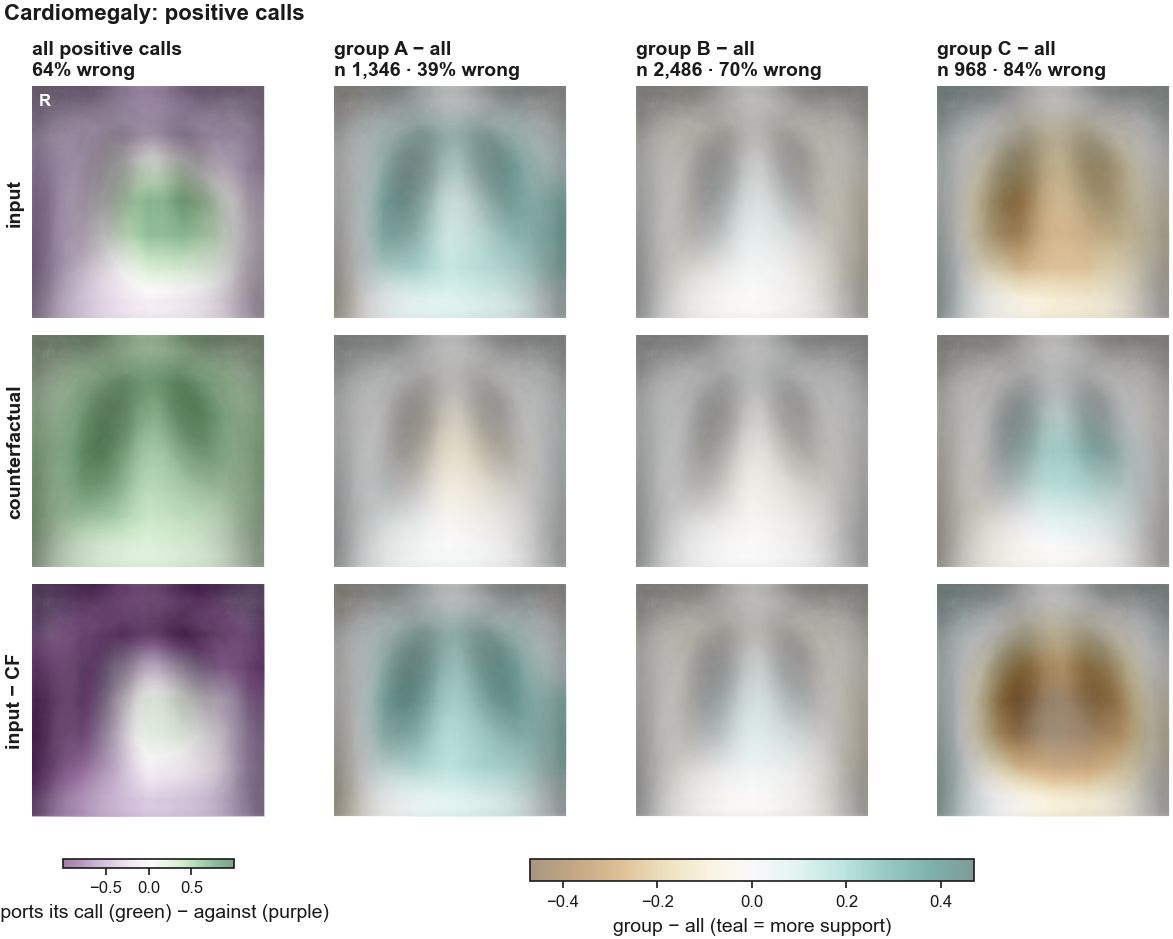

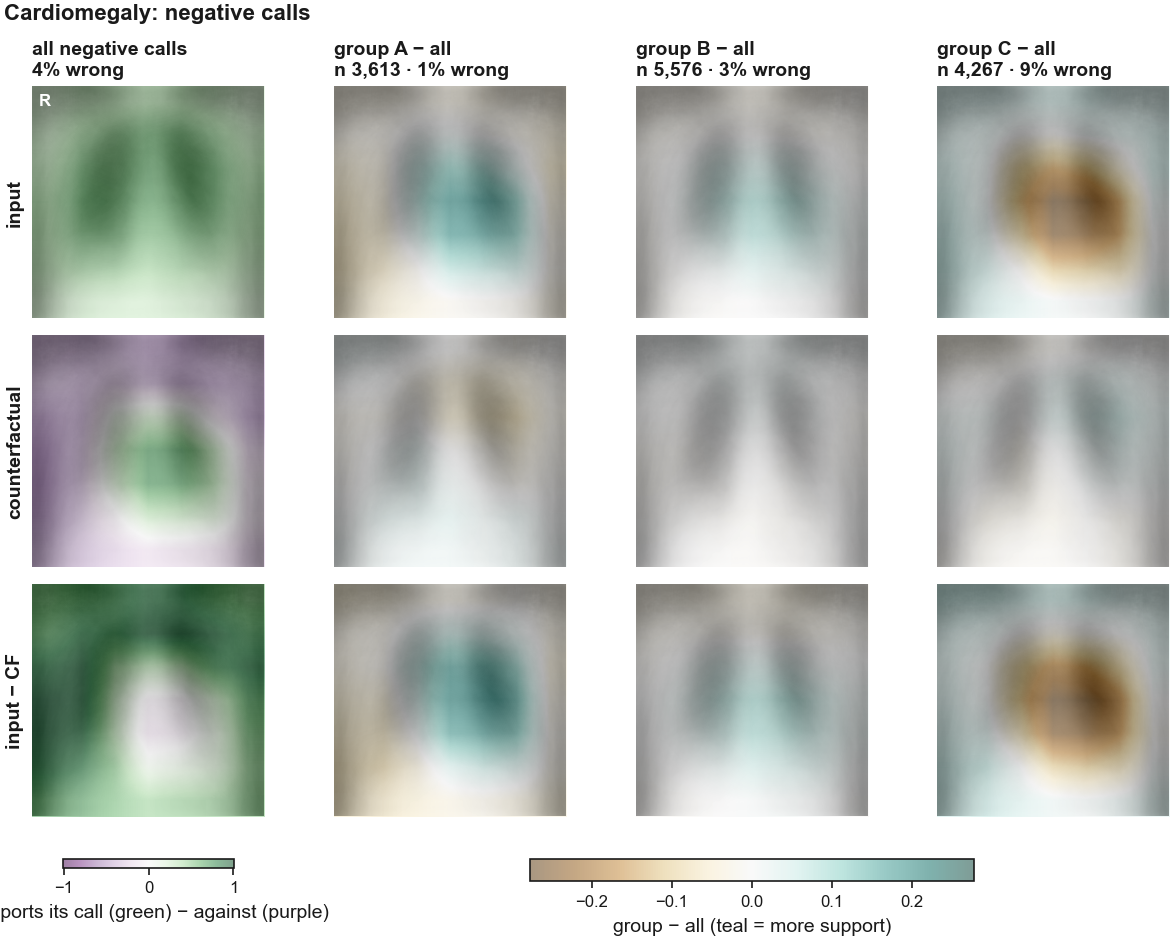

In [27]:
# Grad-CAMs of the fold-4 queries and their nearest CFs, looked up as c2_train_images._load_cam does.
CAM_SPLITS = ("C2_dataset", "Original_Test", "CF_levels")
CAM_BASE   = os.path.join(C0_DIR, "gradcam")

def load_net(img_path):
    """Signed (7, 7) map cam_pos − cam_neg in [-1, 1]."""
    fname = img_path.replace("/", "_") + ".npz"
    for split in CAM_SPLITS:
        fp = os.path.join(CAM_BASE, split, fname)
        if os.path.exists(fp):
            z = np.load(fp)
            return z["cam_pos"] - z["cam_neg"]
    raise FileNotFoundError(f"no Grad-CAM for {img_path!r} under {CAM_BASE}")

# Full-length arrays (NaN outside fold 4), so data's row index addresses them directly.
NET_Q  = np.full((len(data), 7, 7), np.nan, dtype=np.float32)
NET_CF = np.full((len(data), 7, 7), np.nan, dtype=np.float32)
# Oriented by each image's own call: + = supports the call, − = against it. The counterfactual is
# called the other class, so its sign is the opposite of its query's.
# Stacked once and reused across runs (two small .npz per X-ray otherwise), keyed by the X-rays,
# their CFs and C0's calls. The key does not see the Grad-CAM files themselves: delete CAM_CACHE
# after regenerating them.
import hashlib
CAM_CACHE = os.path.join(C2, DISEASE, SOURCE, "gradcam_cache")
cam_key   = hashlib.sha1(repr((CAM_BASE, data.loc[emb_rows, "path"].tolist(),
                               data.loc[emb_rows, "cf_path"].tolist(),
                               pred.loc[emb_rows].tolist())).encode()).hexdigest()[:16]
cam_file  = os.path.join(CAM_CACHE, f"fold{EMB_FOLD}_{cam_key}.npz")
if os.path.exists(cam_file):
    cams = np.load(cam_file)
    NET_Q[emb_rows.values], NET_CF[emb_rows.values] = cams["q"], cams["cf"]
    print(f"fold-4 CAMs: cached ({cam_file})")
else:
    for i in tqdm(emb_rows, desc="fold-4 CAMs"):
        sign = 1.0 if pred.at[i] == 1 else -1.0
        NET_Q[i], NET_CF[i] = sign * load_net(data.at[i, "path"]), -sign * load_net(data.at[i, "cf_path"])
    os.makedirs(CAM_CACHE, exist_ok=True)
    np.savez(cam_file, q=NET_Q[emb_rows.values], cf=NET_CF[emb_rows.values])
    print(f"fold-4 CAMs: loaded, saved to {cam_file}")
MAPS = {"input": NET_Q, "counterfactual": NET_CF, "input − CF": NET_Q - NET_CF}

SIZE, ALPHA = 224, 0.5       # C0 resizes every image to 224 x 224 (no crop): the grid spans the X-ray

def load_xray(path):
    return np.asarray(Image.open(os.path.join(DATA_ROOT, path)).convert("L")
                      .resize((SIZE, SIZE), Image.BILINEAR), dtype=np.float32)

def mean_xray(rows, n=100, seed=0):
    """Average X-ray of a random sample of `rows`, as a neutral background for average maps."""
    rows = np.random.default_rng(seed).choice(np.asarray(rows), min(n, len(rows)), replace=False)
    return np.mean([load_xray(p) for p in data.loc[rows, "path"]], axis=0)

SUPPORT_CMAP, DEV_CMAP = "PRGn", "BrBG"      # green = supports the call, purple = against it

def overlay(ax, bg, m, lim, cmap=SUPPORT_CMAP, mark_r=True):
    """Grey X-ray with a 7x7 map stretched over it."""
    ax.imshow(bg, cmap="gray")
    im = ax.imshow(m, cmap=cmap, vmin=-lim, vmax=lim, alpha=ALPHA, interpolation="bilinear",
                   extent=(0, SIZE, SIZE, 0))
    if mark_r:                                    # patient's right = image left
        ax.text(0.03, 0.97, "R", transform=ax.transAxes, color="white", fontsize=FS["small"],
                fontweight="bold", va="top")
    ax.set_xticks([]); ax.set_yticks([])
    ax.spines[:].set_visible(False)
    return im

PROF_SQ = 30 * MM
for p in SIDES:
    rows = cluster[p].index
    ids  = list(range(N_CLUSTERS, 0, -1))         # group A first
    in_k = {k: rows[(cluster[p] == k).values] for k in ids}
    bg   = mean_xray(rows)
    base = {n: M[rows].mean(axis=0) for n, M in MAPS.items()}
    dev  = {(n, k): M[in_k[k]].mean(axis=0) - base[n] for n, M in MAPS.items() for k in ids}
    lim_b = max(np.abs(v).max() for v in base.values())
    lim_d = max(np.abs(v).max() for v in dev.values())

    fig, axes = plt.subplots(len(MAPS), 1 + N_CLUSTERS, layout="constrained",
                             figsize=((1 + N_CLUSTERS) * PROF_SQ + 34 * MM,
                                      len(MAPS) * (PROF_SQ + 4 * MM) + 18 * MM))
    for r, n in enumerate(MAPS):
        im_b = overlay(axes[r, 0], bg, base[n], lim_b, mark_r=r == 0)
        axes[r, 0].set_ylabel(n, fontweight="bold")
        for c, k in enumerate(ids, 1):
            im_d = overlay(axes[r, c], bg, dev[n, k], lim_d, DEV_CMAP, mark_r=False)
    err = 1 - data["correct"]
    axes[0, 0].set_title(f"all {SIDE_NAME[p].lower()}\n{err[rows].mean():.0%} wrong", fontsize=FS["base"])
    for c, k in enumerate(ids, 1):
        axes[0, c].set_title(f"{GROUP(k)} − all\nn {len(in_k[k]):,} · {err[in_k[k]].mean():.0%} wrong",
                             fontsize=FS["base"])
    fig.colorbar(im_b, ax=axes[:, 0], shrink=0.6, location="bottom", label="supports its call (green) − against (purple)")
    fig.colorbar(im_d, ax=axes[:, 1:], shrink=0.5, location="bottom", label="group − all (teal = more support)")
    fig.suptitle(f"{DISEASE.capitalize()}: {SIDE_NAME[p].lower()}", x=0.01, ha="left")
    save(fig, f"group_maps_{'pos' if p else 'neg'}")
    plt.show()

### 6b. Which part of the CNN separates C0's errors?

*Slow.* Set `RUN_ALL_SPACES = False` in the setup cell to skip the three ablation embeddings and
this figure. Only the embedding of the explained model is computed then, which the case cards
(panel d) need.

The same fold-4 images, grouped and mapped in the embeddings of the CNN ablation. Each column is the
hidden layer of a C2 CNN trained on one combination of the model's input blocks:

| column | model | input blocks |
|---|---|---|
| **a / e** | `xi` | the X-ray |
| **b / f** | `xi_sal` | the X-ray + its saliency map |
| **c / g** | `dual` | the X-ray + its nearest counterfactual |
| **d / h** | `dual_sal` | the X-ray + counterfactual + both saliency maps: the model explained, as in step 6 |

So a → b is the saliency step without the counterfactual, a → c the counterfactual step without
saliency, and d both. Every column is a correctness-trained embedding of fold 4's fold model (the
fold it was not trained on), used as it is: no scaling or PCA, dead units dropped. `xi` is a single
encoder, so its embedding is the 1024-dim pooled DenseNet feature, not a 256-unit hidden layer.
The embeddings come from `code/c2_embed_images.py` (`MODELS=xi+xi_sal+dual`).

In every space the images are clustered with k-means (fit on one patient half of fold 4) and drawn
on their own t-SNE map, using the same sampled images in every column.

* **Colour**: C0's local error rate on the map (share of wrong calls among each point's nearest
  neighbours), centred on the side's overall error rate: yellow = as often wrong as average,
  red = more often, green = less often.
* **Lines and letters**: the k-means groups of that space. Letters are assigned per space by error
  rate (A = lowest), so group A of one column is not the same set of images as group A of another.
  The corner box gives each group's error rate on the held-out half.
* **Error spread**: the gap between the highest and lowest group error rate on the held-out half,
  in percentage points. 0 means the groups are image types that C0 handles equally well; a wide
  spread means the space separates where C0 fails.

If an input block helps separate C0's errors, adding it splits the map further into red and green
regions and widens the error spread. The kNN AUROC per space, against MSP, is in the summary table
printed by the next cell.

In [ ]:
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import KMeans
from sklearn.metrics import roc_auc_score

KNN_K     = 50                                   # neighbours for the kNN AUROC, in the space itself
TSNE_N    = 5000                                 # images per side on the maps (t-SNE is slow)

# The CNN ablation: one C2 CNN per combination of the explained model's input blocks.
ABLATION = {"xi":       "X-ray",
            "xi_sal":   "X-ray + saliency",
            "dual":     "X-ray + CF",
            "dual_sal": "X-ray + CF + saliency"}

def load_embedding(key):
    """Fold-4 embedding of image model `key`, rows aligned with step 6's `emb_rows`, dead units
    dropped."""
    path = os.path.join(k_dir, "images_embeddings", key, f"fold_{EMB_FOLD}.npz")
    assert os.path.exists(path), (f"missing {path}: bsub -env \"all, DISEASE={DISEASE}, "
                                  f"CF_COUNT={BEST_K}, MODELS={key}\" < jobs/c2_embed_images.sh")
    g = np.load(path)
    assert (g["paths"] == f["paths"]).all(), f"{key}: rows differ from the {BEST_MODEL} embedding"
    h = g["h"]
    return pd.DataFrame(h[:, h.std(axis=0) > 0], index=emb_rows)

# name -> (column title, features of rows idx). "C2" is the explained model (step 6's EMB): the case
# cards read its map.
SPACES = {k: (name, lambda idx, E=load_embedding(k): E.loc[idx].values)
          for k, name in ABLATION.items() if k != BEST_MODEL} if RUN_ALL_SPACES else {}
SPACES["C2"] = (ABLATION.get(BEST_MODEL, best["name"]), lambda idx: EMB.loc[idx].values)
ACTIVE_SPACES = SPACES                           # see RUN_ALL_SPACES in setup

def space_features(s, rows, fit):
    """Clustering features of `rows` in space s: the embedding as it is, so the C2 groups reproduce
    step 6. `fit` is unused (no scaling or PCA is fitted)."""
    return SPACES[s][1](rows).astype(float)

def tsne_position(p, row, n_nn=10):
    """Where `row` sits on side p's C2 map. t-SNE cannot place a new point, so a row outside the
    sample is put at the mean position of its n_nn nearest sampled neighbours in the C2 space."""
    idx, emb = TSNE_MAP[p]
    j = idx.get_indexer([row])[0]
    if j >= 0:
        return emb[j]
    d = np.linalg.norm(cluster_space(p, idx) - cluster_space(p, [row])[0], axis=1)
    return emb[np.argsort(d)[:n_nn]].mean(axis=0)

from tsne_cache import cached_tsne
TSNE_CACHE = os.path.join(C2, DISEASE, SOURCE, "tsne_cache")   # maps reused across runs (code/tsne_cache.py)

SPACE_RES = {}                                   # (side, space) -> map, groups and metrics
TSNE_MAP  = {}                                   # side -> (sampled rows, C2 map), for the case cards
for p, title in SIDES.items():
    rows = emb_rows[(pred.loc[emb_rows] == p).values]
    fit  = fit_half.loc[rows].values
    ok   = data.loc[rows, "correct"].values.astype(int)
    idx  = rows[np.random.default_rng(42).choice(len(rows), min(TSNE_N, len(rows)), replace=False)]
    pos  = rows.get_indexer(idx)

    for s, (name, _) in ACTIVE_SPACES.items():
        X      = space_features(s, rows, fit)
        labels = KMeans(N_CLUSTERS, n_init=10, random_state=42).fit(X[fit]).predict(X)
        groups = summarise_groups(f"{title} · {name}", rows, labels, ~fit, N_CLUSTERS)

        # kNN correctness: neighbours from the fitting half, scored on the held-out half
        _, nb   = NearestNeighbors(n_neighbors=KNN_K).fit(X[fit]).kneighbors(X[~fit])
        knn_auc = roc_auc_score(ok[~fit], ok[fit][nb].mean(axis=1))

        emb    = cached_tsne(X[pos], TSNE_CACHE,
                             f"img_{BEST_MODEL if s == 'C2' else s}_K{BEST_K}_side{p}")
        err_ho = {k: 1 - ok[~fit][groups.values[~fit] == k].mean() for k in range(N_CLUSTERS, 0, -1)}
        SPACE_RES[p, s] = dict(idx=idx, emb=emb, groups=groups.loc[idx].values,
                               err_ho=err_ho, knn_auc=knn_auc)
    SPACE_RES[p, "MSP"] = roc_auc_score(ok[~fit], msp[rows][~fit])
    TSNE_MAP[p] = (idx, SPACE_RES[p, "C2"]["emb"])

# One table for the text: does each input block add structure?
summary = pd.DataFrame([
    {"side": SIDE_NAME[p], "space": SPACES[s][0],
     "kNN AUROC": SPACE_RES[p, s]["knn_auc"],
     "group error spread (held-out)": max(SPACE_RES[p, s]["err_ho"].values())
                                      - min(SPACE_RES[p, s]["err_ho"].values()),
     "MSP AUROC": SPACE_RES[p, "MSP"]}
    for p in SIDES for s in ACTIVE_SPACES])
display(summary.set_index(["side", "space"]).round(3))

In [ ]:
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from scipy.ndimage import gaussian_filter, distance_transform_edt
from matplotlib.colors import TwoSlopeNorm
from matplotlib.collections import Collection
import matplotlib.patheffects as pe

SPACE_SQ  = 38 * MM                              # square map panel
DOT_SIZE  = 3                                    # scatter marker area (pt²)
LOCAL_K   = max(10, TSNE_N // 100)              # neighbours for the local error rate
SPAN      = {1: 0.30, 0: 0.15}                   # colour range either side of the side's error rate
HALO      = [pe.withStroke(linewidth=1.8, foreground="white")]
ERR_CMAP  = "RdYlGn_r"                           # green = less often wrong, yellow = average, red = more

def map_limits(emb, q=0.5, pad=0.06):
    """Axis limits from the 0.5-99.5 percentile of the map, so stray points do not shrink it."""
    lo, hi = np.percentile(emb, [q, 100 - q], axis=0)
    return lo - pad * (hi - lo), hi + pad * (hi - lo)

def territories(ax, emb, labels, lims, n_grid=250, k=50, sigma=3):
    """Smoothed borders between the groups' regions on the map, and each group's letter at the most
    interior point of its region (farthest from any border or blank area). Each group's share among
    a grid cell's k nearest points is smoothed; a border runs where two groups' shares are equal.
    Cells far from any point stay blank."""
    lo, hi = emb.min(axis=0), emb.max(axis=0)
    gx, gy = np.meshgrid(*[np.linspace(l, h, n_grid) for l, h in zip(lo, hi)])
    G      = np.c_[gx.ravel(), gy.ravel()]
    ids    = np.unique(labels)
    P      = KNeighborsClassifier(k).fit(emb, labels).predict_proba(G).reshape(*gx.shape, len(ids))
    P      = np.stack([gaussian_filter(P[..., i], sigma) for i in range(len(ids))], axis=-1)
    d, _   = NearestNeighbors(n_neighbors=1).fit(emb).kneighbors(G)
    far    = gaussian_filter((d.reshape(gx.shape) > 0.03 * (hi - lo).max()).astype(float), 2) > 0.5
    shown  = ((gx > lims[0][0]) & (gx < lims[1][0]) & (gy > lims[0][1]) & (gy < lims[1][1]))
    win    = P.argmax(axis=-1)

    for i, g in enumerate(ids):
        margin = np.ma.masked_where(far, P[..., i] - np.delete(P, i, axis=-1).max(axis=-1))
        cs = ax.contour(gx, gy, margin, levels=[0], colors=INK, linewidths=0.7, zorder=3)
        for c in ([cs] if isinstance(cs, Collection) else cs.collections):
            c.set_path_effects(HALO)

        region = (win == i) & ~far & shown
        if not region.any():
            continue
        depth = distance_transform_edt(np.pad(region, 1))[1:-1, 1:-1]   # distance to the region's edge
        j = np.unravel_index(depth.argmax(), depth.shape)
        t = ax.text(gx[j], gy[j], GROUP(g)[-1], ha="center", va="center", fontsize=FS["base"],
                    fontweight="bold", color=INK, zorder=5, clip_on=True,
                    bbox=dict(boxstyle="circle,pad=0.2", facecolor="white", edgecolor=INK,
                              lw=0.4, alpha=0.9))
        t.set_in_layout(False)                   # never shrinks the panel

def group_rates(ax, err):
    """Each group's held-out error rate, stacked in the panel's lower-right corner."""
    lines = ["wrong"] + [f"{GROUP(k)[-1]}  {e:.0%}" for k, e in err.items()]
    ax.text(0.99, 0.01, "\n".join(lines), transform=ax.transAxes, ha="right", va="bottom",
            fontsize=FS["base"], color=INK, linespacing=1.25, zorder=6,
            bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor=HAIR, lw=0.4,
                      alpha=0.9))

if RUN_ALL_SPACES:            # the four-spaces figure; the helpers above are always needed
    # One column per ablation embedding, the explained model last.
    fig  = plt.figure(figsize=(FULL, len(SIDES) * (SPACE_SQ + 16 * MM) + 6 * MM), layout="constrained")
    axes = fig.subplots(len(SIDES), len(SPACES), squeeze=False)
    tighten(fig)

    letters = iter("abcdefgh")
    for row, p in zip(axes, SIDES):
        rows = emb_rows[(pred.loc[emb_rows] == p).values]
        base = 1 - data.loc[rows, "correct"].mean()
        norm = TwoSlopeNorm(vcenter=base, vmin=max(0, base - SPAN[p]), vmax=min(1, base + SPAN[p]))

        for ax, (s, (name, _)) in zip(row, SPACES.items()):
            r = SPACE_RES[p, s]
            idx, emb, lab = r["idx"], r["emb"], r["groups"]
            lims = map_limits(emb)

            # C0's local error rate: share of wrong calls among each point's LOCAL_K map neighbours
            _, nb     = NearestNeighbors(n_neighbors=LOCAL_K).fit(emb).kneighbors(emb)
            local_err = 1 - data.loc[idx, "correct"].values[nb].mean(axis=1)
            sc = ax.scatter(*emb.T, c=local_err, cmap=ERR_CMAP, norm=norm, s=DOT_SIZE, lw=0,
                            rasterized=True)
            territories(ax, emb, lab, lims)
            group_rates(ax, r["err_ho"])

            # header: panel name, then the error spread (held-out, highest minus lowest group)
            spread = max(r["err_ho"].values()) - min(r["err_ho"].values())
            ax.set_title(f"{next(letters)}   {name}", loc="left", pad=14)
            ax.text(0, 1.02, f"error spread {spread * 100:.1f} pts", transform=ax.transAxes,
                    fontsize=FS["head"], fontweight="bold", color=MUTED, va="bottom")

            ax.set_xlim(lims[0][0], lims[1][0]); ax.set_ylim(lims[0][1], lims[1][1])
            ax.set_xticks([]); ax.set_yticks([])
            ax.spines[["left", "bottom"]].set_visible(False)
            ax.set_aspect("equal", adjustable="datalim")
            ax.set_box_aspect(1)

        row[0].set_ylabel(f"{SIDE_NAME[p]}\n{base:.0%} wrong", fontweight="bold", labelpad=4)
        cb = fig.colorbar(sc, ax=list(row), shrink=0.8, aspect=18, pad=0.02, label="local C0 error rate")
        cb.set_ticks([norm.vmin, base, norm.vmax],
                     labels=[f"{norm.vmin:.0%}", f"{base:.0%} (all)", f"{norm.vmax:.0%}"])

    fig.align_ylabels(axes[:, 0])
    fig.suptitle(f"{DISEASE.capitalize()}: where C0 is wrong, in the CNN ablation's embeddings",
                 x=0.01, ha="left")

    save(fig, "tsne_spaces")
    plt.show()
else:
    print("RUN_ALL_SPACES = False: four-spaces figure skipped (the case cards use the CNN map only)")

## 7. Case cards

One image taken through the pipeline, one square panel per step:

| panel | step |
|---|---|
| **a** C0's call | the X-ray with the map **supporting** C0's call (green; organs of the profile outlined): what C0 predicts, with what probability, and whether it was right |
| **b** Evidence against the call | the same X-ray with the map **against** C0's call (purple), on the same 0-1 scale |
| **c** Where its evidence sits | the side's key regions (step 4; all four, the group profiles draw the top three) and Outside: **this X-ray's** support (●) and against (✕) focus in organ colour, **its group's average** in grey beside it, SD units of the side |
| **d** Where C0 is wrong | the CNN map of step 6b: local error rate (green = safer, yellow = average, red = riskier), group borders and letters, this image as a star |
| **e** Similar past cases | the four members closest to its group's centre, with their saliency maps, tagged with their outcome |
| **f** How often C0 is wrong | errors per 100 in this image's group vs the side's other calls; bar in the map's colour |
| **g** How much to trust this call | trust meter: ▼ C2 rank and △ MSP rank, with the deferral cut at `COVERAGE` |
| **h** Key | every legend of the card |

No counterfactual: this explanation reads only the X-ray's own two maps (the counterfactual's maps
look like any correct call, step 6). **Colours on every X-ray**: green = evidence supporting C0's
call, purple = evidence against it; the similar cases (e) show both at once and share the query's
call. Panel c and the outlines use the side's key regions (step 4), lung halves outlined as
halves.

The caption (title chain, error rates, ranks, deferral verdicts) is written to a `.txt` beside each
saved card. On the map, an image outside the t-SNE sample is placed at the mean position of its 10
nearest sampled neighbours in the CNN embedding (t-SNE cannot embed a new point).

Needs the step-6b cells: the case-card cell uses their C2 map (`TSNE_MAP`), colour scale and group
borders.

**Ranks and coverage.** `SCORE_SCOPE = "all"` ranks every call of a fold together, as E-AURC and the
risk-coverage curves do, so `COVERAGE` (one global cut for every card) is the real deferral cut;
`"side"` ranks within C0's call.

**`pick_case`** chooses the example: a **held-out** image (its group was fit without it), with the
wanted outcome, among the most typical half of its group, with the clearest assignment.
* `c2="agree"` keeps images where C2 clearly points the right way (top third of C2 ranks for a
  correct call, bottom third for a wrong one), `"disagree"` the opposite, `None` ignores it.
* `c2_cut` / `msp_cut` = `"accept"` or `"defer"`: where C2 / MSP put the call at `COVERAGE`, at
  least `margin` away from the cut.
* `nth` picks a runner-up from the printed table; any of its row numbers can also go straight to
  `case_card`.

In [ ]:
import textwrap
from sklearn.neighbors import NearestNeighbors
from matplotlib.ticker import PercentFormatter
from matplotlib.legend_handler import HandlerTuple
from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap

# The error map in panel d is the CNN map of the four-spaces figure: its sample, colours and groups.
_missing = [n for n in ("TSNE_MAP", "territories", "map_limits", "ERR_CMAP", "SPAN", "LOCAL_K")
            if n not in globals()]
assert not _missing, f"run the four-spaces cells (compute + figure) first; missing: {_missing}"

DATA_ROOT      = os.environ.get("THESIS_DATA", "/work3/s251710/thesis_data")
LETTERS        = "ABCDEFGHIJ"
SEG_ON_TYPICAL = True      # also draw the organs on the four typical images of the group
SCORE_SCOPE = "all"    # trust ranks: "all" = every call of the image's fold, as E-AURC ranks them
                       # (one global deferral cut); "side" = only calls with the same C0 call
COVERAGE    = 0.80     # ONE global coverage for every card: C2 keeps this share of all calls in a
                       # fold (positive and negative together), defers the least trusted rest

SEG_ON_TYPICAL = False     # the four typical images carry their saliency maps; outlines would clutter them
CAM_ALPHA      = 0.45      # opacity of the saliency map over the X-ray
DISPLAY_SIZE   = 320       # every image is drawn as a DISPLAY_SIZE x DISPLAY_SIZE square (resized, not cropped)
CARD_DOT       = globals().get("DOT_SIZE", 3)   # map dot size, as in the four-spaces figure

# ── Organ segmentation: the PSPNet the C1 attributes were measured with, same preprocessing ──
# Model and mask cache survive re-running this cell (segmenting is the slow part of a card);
# on a GPU node the model runs there.
SEG_DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if "SEG_MODEL" not in globals():
    SEG_MODEL = xrv.baseline_models.chestx_det.PSPNet().eval()
SEG_MODEL  = SEG_MODEL.to(SEG_DEVICE)
SEG_RESIZE = xrv.datasets.XRayResizer(224)
_seg_cache = globals().get("_seg_cache", {})

def organ_masks(path):
    """{organ: binary mask at DISPLAY_SIZE x DISPLAY_SIZE}, preprocessed exactly as in C1."""
    if path not in _seg_cache:
        img = np.asarray(Image.open(os.path.join(DATA_ROOT, path)).convert("L"), dtype=np.float32)
        x = SEG_RESIZE(xrv.datasets.normalize(img, 255)[None])        # (1, 224, 224), [-1024, 1024]
        with torch.no_grad(), warnings.catch_warnings():
            warnings.simplefilter("ignore")                            # "224 is not native 512": same as C1
            out = torch.sigmoid(SEG_MODEL(torch.from_numpy(x)[None].to(SEG_DEVICE))).cpu().numpy()[0]
        _seg_cache[path] = {
            name: np.asarray(Image.fromarray((m >= 0.5).astype(np.uint8))
                             .resize((DISPLAY_SIZE, DISPLAY_SIZE), Image.NEAREST))
            for name, m in zip(SEG_MODEL.targets, out)}
    return _seg_cache[path]


# Panel c and the organ outlines use the side's key regions (step 4, all N_KEEP), Outside last.
# A saliency region is a union of PSPNet structures (c1_region_masks.REGIONS); its outline is
# drawn as those structures. Outside and the whole-map measures have none.
from c1_region_masks import REGIONS
REGION_STRUCTS = {r: list(src or []) for r, src in REGIONS.items()}
REGION_STRUCTS.update({"Left Lung upper": ["Left Lung"], "Left Lung lower": ["Left Lung"],
                       "Right Lung upper": ["Right Lung"], "Right Lung lower": ["Right Lung"],
                       "Heart-Left Lung overlap": ["Heart", "Left Lung"],
                       "Lung asymmetry": ["Left Lung", "Right Lung"]})

# From the group-profile cell (step 6); fallbacks so this cell also runs if that one was skipped.
SHOW_OUTSIDE = globals().get("SHOW_OUTSIDE", True)
if "ZO" not in globals():
    ZO = zframe("opp_")                          # X-ray against, SD units within the side
assert "pair_dumbbells" in globals(), "run the group-profile cell (step 6) first: panel c uses its marks"

def profile_regions(p):
    """Side p's regions for the case cards: all key regions (step 4), then Outside if shown. The
    group-profile figure (step 6) draws only the top N_PROFILE of them."""
    return [r for r in SEL[p] if r != "Outside"] + (["Outside"] if SHOW_OUTSIDE else [])

def case_organs(p, k):
    """The regions drawn for side p that can be outlined (Outside is the absence of every mask)."""
    return [r for r in profile_regions(p) if r != "Outside"]

def region_masks(path, regions):
    """{region: mask at DISPLAY_SIZE}, built from the PSPNet structures exactly as
    c1_region_masks.py builds the regions: unions, the heart-left-lung overlap, and lung halves
    split at the middle row of the lung's own bounding box."""
    m, out = organ_masks(path), {}
    for r in regions:
        if r == "Heart-Left Lung overlap":
            mk = m["Heart"].astype(bool) & m["Left Lung"].astype(bool)
        elif r.endswith((" upper", " lower")):
            lung = m[r.rsplit(" ", 1)[0]].astype(bool)
            rows = np.where(lung.any(axis=1))[0]
            mid  = (rows.min() + rows.max()) / 2 if len(rows) else 0
            up   = np.arange(lung.shape[0])[:, None] <= mid
            mk   = lung & (up if r.endswith("upper") else ~up)
        else:
            mk = np.any([m[s].astype(bool) for s in REGION_STRUCTS.get(r, [r])], axis=0)
        out[r] = mk.astype(np.uint8)
    return out

def overlay_organs(ax, path, organs, alpha=0.22, lw=0.9):
    """Each region: full outline in its legend colour, soft transparent fill."""
    masks = region_masks(path, organs)
    for organ in organs:
        m = masks.get(organ)
        if m is None or not m.any():
            continue
        c = organ_color(organ)
        ax.contourf(m, levels=[0.5, 1.5], colors=[to_rgba(c, alpha)])
        ax.contour(m, levels=[0.5], colors=[c], linewidths=lw)

# ── Case selection and drawing ──
def group_geometry(p):
    """Clustering-space coordinates and group centres for side p."""
    rows = cluster[p].index
    X    = pd.DataFrame(cluster_space(p, rows), index=rows)
    return X, X.groupby(cluster[p]).mean()

# Trust ranks (0 = least, 1 = most trusted) of C2 and MSP, for the trust meter and pick_case.
# "all": within each fold over positive AND negative calls -- the ranking E-AURC and the
# risk-coverage curves use, so the COVERAGE cut is the real one. "side": within C0's call,
# pooled over folds.
RANK_KEYS  = {"all": [data["fold"]], "side": [pred]}[SCORE_SCOPE]
SCOPE_TEXT = {"all": "all calls", "side": None}[SCORE_SCOPE]  # None: "{side} calls", per card
data["c2_rank"]  = data["model_score"].groupby(RANK_KEYS).rank(pct=True)
data["msp_rank"] = pd.Series(msp, index=data.index).groupby(RANK_KEYS).rank(pct=True)

def pick_case(p, group, outcome="correct", n_show=5, c2="agree", c2_cut=None, msp_cut=None,
              margin=0.05, nth=0):
    """Row of a typical, clearly assigned held-out image of `group` ('A', 'B'...) on side p.

    c2="agree": C2 clearly points the right way (top third of C2 ranks for a correct call,
    bottom third for a wrong one); "disagree": clearly the wrong way; None: not used.
    All ranks are the SCORE_SCOPE ranks (c2_rank / msp_rank), as drawn on the trust meter.
    c2_cut / msp_cut: "accept" or "defer": where C2 / MSP put the call at COVERAGE, at least
    `margin` away from the cut so the verdict on the trust meter is not a coin flip; None: not used.
    nth: which candidate of the ranked table to return (0 = the clearest).
    """
    assert group in LETTERS[:N_CLUSTERS], f"only groups {LETTERS[:N_CLUSTERS]} exist"
    k      = N_CLUSTERS - LETTERS.index(group)                  # letter -> internal cluster id
    X, centres = group_geometry(p)
    in_k   = cluster[p].index[(cluster[p] == k).values]
    cand   = in_k[held_out.loc[in_k].values]                     # not seen by k-means
    if outcome is not None:
        cand = cand[data.loc[cand, "correct"].values == (outcome == "correct")]
    if c2 is not None:
        pct     = data.loc[cand, "c2_rank"].values
        correct = data.loc[cand, "correct"].values == 1
        right   = np.where(correct, pct >= 2 / 3, pct <= 1 / 3)       # C2 clearly right
        wrong   = np.where(correct, pct <= 1 / 3, pct >= 2 / 3)       # C2 clearly wrong
        cand    = cand[right if c2 == "agree" else wrong]
    thr = 1 - COVERAGE                                           # trust-meter cut (rank)
    for col, cut in [("c2_rank", c2_cut), ("msp_rank", msp_cut)]:
        if cut is not None:
            v    = data.loc[cand, col].values
            cand = cand[v >= thr + margin if cut == "accept" else v < thr - margin]
    assert len(cand), "no candidate matches these filters (try a smaller margin, or c2=None)"

    dist  = pd.DataFrame(np.linalg.norm(X.loc[cand].values[:, None, :] - centres.values[None], axis=2),
                         index=cand, columns=centres.index)
    a     = profile_regions(p)                                # both maps: support and against
    both  = pd.concat([ZS[a].add_prefix("sup "), ZO[a].add_prefix("opp ")], axis=1)
    gap   = (both.loc[cand] - both.loc[in_k].mean()).abs().mean(axis=1)
    score = pd.DataFrame({"clearness": dist.drop(columns=k).min(axis=1) / dist[k],
                          "profile gap": gap, "outcome": quadrant[cand],
                          "C2 rank": data.loc[cand, "c2_rank"],
                          "MSP rank": data.loc[cand, "msp_rank"],
                          "path": data.loc[cand, "path"]})
    score = score[score["profile gap"] <= score["profile gap"].median()]
    score = score.sort_values("clearness", ascending=False)
    print(f"{len(score)} candidates")
    display(score.head(max(n_show, nth + 1)).round(3))
    return score.index[nth]

STAR = "#FFC20A"

# Plain-language outcome of each call, for the panels (the caption keeps TP/FP, C0, C2)
OUTCOME = {"TP": "✓ true positive", "TN": "✓ true negative",
           "FP": "✗ false positive", "FN": "✗ false negative"}
TAG     = {q: v.replace(" ", "\n", 2).replace("\n", " ", 1)     # "✓ true\npositive": fits the
           for q, v in OUTCOME.items()}                            # small images in e
GLYPHS  = ["Arial", "DejaVu Sans"]                # Arial has no ✓ ✗ △: fall back to DejaVu for those

# ── Case-card grid (mm): 4 x 2 equal squares, equal gaps, every title at the same height ──
CARD_W  = FULL / MM                               # 183 mm
CARD_M  = 4                                       # left / right margin
CARD_G  = 9                                       # gap between columns
CARD_S  = (CARD_W - 2 * CARD_M - 3 * CARD_G) / 4  # side of one square panel (37 mm)
CARD_HD = 3                                       # top margin (the caption goes to a .txt beside the figure)
CARD_T  = (11, 14)                                # per row: title lines (2, then 3 for e) + subtitle
CARD_R  = 9                                       # tick labels / x label under the first row
CARD_B  = 4                                       # under the second row
CARD_H  = CARD_HD + sum(CARD_T) + 2 * CARD_S + CARD_R + CARD_B
TITLE_LINE = 3.2                                  # mm per title line (7.5 pt)
TITLE_WRAP = 28                                   # characters per title line (fits square + gap)

def card_cell(r, c):
    """[left, bottom, width, height] (figure fraction) of the square in row r, column c."""
    top = CARD_HD + CARD_T[0] + r * (CARD_S + CARD_R + CARD_T[1])
    x   = CARD_M + c * (CARD_S + CARD_G)
    return [x / CARD_W, 1 - (top + CARD_S) / CARD_H, CARD_S / CARD_W, CARD_S / CARD_H]

def card_title(fig, r, c, letter, head, sub=""):
    """Panel letter + bold title (wrapped onto a second line if needed, or at an explicit '\n'),
    muted subtitle right under it. The first title line sits at the same height in every panel."""
    x, y, _, h = card_cell(r, c)
    y_top = y + h + (CARD_T[r] - 0.5) / CARD_H
    lines = head.split("\n") if "\n" in head else textwrap.wrap(head, TITLE_WRAP)
    kw = dict(fontsize=FS["title"], fontweight="bold", va="top", linespacing=1.15)
    fig.text(x, y_top, letter, **kw)
    fig.text(x + 3.4 / CARD_W, y_top, "\n".join(lines), **kw)
    fig.text(x, y_top - (len(lines) * TITLE_LINE + 0.6) / CARD_H, sub, fontsize=FS["small"],
             color=MUTED, va="top", fontfamily=GLYPHS)

def per100(v):
    """Error rate as a natural frequency: 0.087 -> '9 in 100'."""
    return f"{100 * v:.0f} in 100" if v >= 0.005 else f"{1000 * v:.0f} in 1,000"

SUP_C, OPP_C = plt.get_cmap(SUPPORT_CMAP)(0.85), plt.get_cmap(SUPPORT_CMAP)(0.15)
FADE = {m: LinearSegmentedColormap.from_list(m, [to_rgba(c, 0), to_rgba(c, CAM_ALPHA + 0.3)])
        for m, c in [("sup", SUP_C), ("opp", OPP_C)]}       # transparent -> colour: 0 shows the X-ray

def load_maps(path, call):
    """(support, against) maps of C0's call on this image, each (7, 7) in [0, 1] (C0 stores each
    map scaled to max 1; the two never overlap)."""
    fname = path.replace("/", "_") + ".npz"
    for split in CAM_SPLITS:
        fp = os.path.join(CAM_BASE, split, fname)
        if os.path.exists(fp):
            z = np.load(fp)
            return (z["cam_pos"], z["cam_neg"]) if call == 1 else (z["cam_neg"], z["cam_pos"])
    raise FileNotFoundError(f"no Grad-CAM for {path!r} under {CAM_BASE}")

def show(ax, path, call, title="", size=FS["small"], organs=(), tag=None, cam="both"):
    """The X-ray, its saliency oriented by C0's call on THIS image and the region outlines.
    cam: "sup" = only the map supporting the call (green), "opp" = only the map against it
    (purple), "both" = the signed map (green / purple), None = no map."""
    img = (Image.open(os.path.join(DATA_ROOT, path)).convert("L")
           .resize((DISPLAY_SIZE, DISPLAY_SIZE), Image.BILINEAR))
    ax.imshow(img, cmap="gray")
    ext = (-0.5, DISPLAY_SIZE - 0.5, DISPLAY_SIZE - 0.5, -0.5)
    if cam == "both":
        ax.imshow((1 if call == 1 else -1) * load_net(path), cmap=SUPPORT_CMAP, vmin=-1, vmax=1,
                  alpha=CAM_ALPHA, interpolation="bilinear", extent=ext)
    elif cam in ("sup", "opp"):
        m = load_maps(path, call)[cam == "opp"]
        ax.imshow(m, cmap=FADE[cam], vmin=0, vmax=1, interpolation="bilinear", extent=ext)
    overlay_organs(ax, path, organs)
    ax.axis("off")
    if tag:                                              # small label inside the image corner
        ax.text(0.03, 0.97, tag, transform=ax.transAxes, color="white", fontsize=FS["small"],
                fontweight="bold", va="top", ha="left", fontfamily=GLYPHS,
                bbox=dict(facecolor=INK, alpha=0.65, lw=0, pad=1.2))

GROUP_C, OFFSET = "#9A9A9A", 0.2                  # group average: grey, left of this X-ray

def case_profile(ax, p, row, in_k):
    """Panel c: this X-ray's support (●) and against (✕) focus in organ colour (the group-profile
    marks), its group's average in grey just left of it; SD units of the side."""
    regs = profile_regions(p)
    sup, opp   = ZS.loc[row, regs], ZO.loc[row, regs]
    gsup, gopp = ZS.loc[in_k, regs].mean(), ZO.loc[in_k, regs].mean()
    pair_dumbbells(ax, regs, sup, opp)                     # this X-ray, centred on each region
    for xi, r in enumerate(regs):                          # its group's average, in grey
        x = xi - OFFSET
        ax.plot([x, x], [gsup[r], gopp[r]], color=GROUP_C, lw=DB["line"] * 0.6, alpha=0.5,
                solid_capstyle="butt", zorder=1.5)
        ax.scatter(x, gsup[r], s=DB["dot"] * 0.7, color=GROUP_C, edgecolor="white",
                   lw=DB["edge"], zorder=1.6)
        ax.scatter(x, gopp[r], s=DB["dot"] * 0.8, marker="X", color=GROUP_C, edgecolor="white",
                   lw=DB["edge"], zorder=1.6)
    vals = pd.concat([sup, opp, gsup, gopp]).dropna()
    pad  = 0.15 * max(1.0, vals.max() - vals.min())
    ax.set_ylim(min(vals.min(), 0) - pad, max(vals.max(), 0) + pad)
    ax.set_ylabel("focus (SD)", fontsize=FS["tiny"], labelpad=1)
    ax.tick_params(axis="y", labelsize=FS["tiny"])

ACCEPT_C, DEFER_C = "#1A7F37", "#B2182B"          # verdict colours (green / red ends of the bar)

def trust_meter(ax, c2_pct, msp_pct):
    """One bar from least to most trusted (rank among the shown calls): ▼ C2 above the bar,
    △ MSP below it, so a disagreement between the two is visible at a glance. The dashed line is
    the deferral threshold at COVERAGE: calls left of it go to a radiologist."""
    ax.imshow(np.linspace(0, 1, 256)[None], extent=[0, 1, 0.44, 0.56], aspect="auto",
              cmap="RdYlGn", zorder=1)
    ax.set_xlim(-0.03, 1.03); ax.set_ylim(0, 1); ax.axis("off")
    thr = 1 - COVERAGE                                   # rank below which a call is deferred
    ax.plot([thr, thr], [0.40, 0.60], color=INK, lw=LW["ref"], ls="--", zorder=2)
    ax.text(thr / 2, 0.5, "defer", ha="center", va="center", fontsize=FS["tiny"],
            color="white", fontweight="bold", zorder=2)
    ax.text((1 + thr) / 2, 0.5, "accept", ha="center", va="center", fontsize=FS["tiny"],
            color=INK, fontweight="bold", zorder=2)
    accepted = c2_pct >= thr
    ax.text(0, 0.99, f"At {COVERAGE:.0%} coverage: {'ACCEPTED' if accepted else 'DEFERRED'}",
            ha="left", va="top", fontsize=FS["base"], fontweight="bold",
            color=ACCEPT_C if accepted else DEFER_C)
    ax.text(0, 0.90, f"C0's own confidence alone: {'accepted' if msp_pct >= thr else 'deferred'}",
            ha="left", va="top", fontsize=FS["tiny"], color=MUTED)
    def ha(v):                                           # keep the labels inside the square
        return "left" if v < 0.2 else "right" if v > 0.8 else "center"
    ax.scatter([c2_pct], [0.62], marker="v", s=55, color=INK, lw=0, zorder=3)
    ax.text(c2_pct, 0.68, f"trust check\nabove {c2_pct:.0%}", ha=ha(c2_pct), va="bottom",
            fontsize=FS["small"], fontweight="bold", color=INK, linespacing=1.1)
    ax.scatter([msp_pct], [0.38], marker="^", s=55, facecolor="white", edgecolor=INK, lw=0.9,
               zorder=3)
    ax.text(msp_pct, 0.32, f"C0's own confidence\nabove {msp_pct:.0%}", ha=ha(msp_pct), va="top",
            fontsize=FS["small"], color=MUTED, linespacing=1.1)
    ax.text(0, 0.02, "least trusted", ha="left", va="bottom", fontsize=FS["tiny"], color=MUTED)
    ax.text(1, 0.02, "most trusted", ha="right", va="bottom", fontsize=FS["tiny"], color=MUTED)

def group_misses(ax, p, k, color):
    """How often C0 is wrong for this image's group vs the rest of the side, as 'N in 100'. Both on
    the held-out half of fold 4 (the rows k-means did not see), as everywhere the groups' error
    rates are reported. `color` is the caller's (whole-group) bar colour."""
    rows = cluster[p].index
    rows = rows[held_out.loc[rows].values]
    err  = 1 - data.loc[rows, "correct"]
    in_k = (cluster[p].loc[rows] == k).values
    vals = [err[in_k].mean(), err[~in_k].mean()]
    labs = [f"cases like this one ({GROUP(k)})", f"other {'positive' if p else 'negative'} calls"]
    y    = np.arange(2)
    ax.barh(y, vals, height=0.45, color=[color, HAIR], edgecolor=[INK, "none"], lw=0.4)
    for yi, v, lab, bold in zip(y, vals, labs, [True, False]):
        ax.text(0.01, yi - 0.29, lab, transform=ax.get_yaxis_transform(), va="bottom",
                fontsize=FS["small"], color=INK)
        ax.text(v, yi, f"  {per100(v)}", va="center", fontsize=FS["head"] if bold else FS["base"],
                fontweight="bold" if bold else "normal", color=INK)
    ax.set_ylim(1.5, -0.85)
    ax.set_xlim(0, max(vals) * 1.7)                     # room for the "N in 100" labels
    ax.set_yticks([]); ax.xaxis.set_visible(False)
    ax.spines["bottom"].set_visible(False)
    return vals

def side_norm(p):
    """The four-spaces colour scale of side p: centred on the side's error rate, SPAN either way."""
    base = 1 - data.loc[cluster[p].index, "correct"].mean()
    return TwoSlopeNorm(vcenter=base, vmin=max(0, base - SPAN[p]), vmax=min(1, base + SPAN[p]))

def error_colour(p, e):
    """Colour of error rate e on side p's scale (green = safer, yellow = average, red = riskier)."""
    return plt.get_cmap(ERR_CMAP)(side_norm(p)(e))

def local_error(p):
    """C0's error rate among each map point's LOCAL_K nearest neighbours on side p's C2 map (as in
    the four-spaces figure). Recomputed every time: cheap, and never stale after a disease switch."""
    idx, emb = TSNE_MAP[p]
    _, nb = NearestNeighbors(n_neighbors=LOCAL_K).fit(emb).kneighbors(emb)
    return 1 - data.loc[idx, "correct"].values[nb].mean(axis=1)

def error_map(ax, p, row):
    """Side p's C2 map as in the four-spaces figure (local error rate, green-yellow-red around the
    side's error rate, group borders and letters), with `row` as a star."""
    idx, emb = TSNE_MAP[p]
    norm = side_norm(p)
    (x0, y0), (x1, y1) = map_limits(emb)
    sc = ax.scatter(*emb.T, c=local_error(p), cmap=ERR_CMAP, norm=norm, s=CARD_DOT, lw=0,
                    rasterized=True)
    territories(ax, emb, cluster[p].loc[idx].values, ((x0, y0), (x1, y1)))
    x, y = tsne_position(p, row)
    ax.scatter([x], [y], marker="*", s=220, color=STAR, edgecolor=INK, lw=1.0, zorder=7)
    right = (x - x0) / (x1 - x0) > 0.6                   # label on the inner side of the star
    ax.annotate("this X-ray", (x, y), xytext=(-7 if right else 7, 7), textcoords="offset points",
                ha="right" if right else "left", fontsize=FS["small"], fontweight="bold", color=INK,
                zorder=7, bbox=dict(facecolor="white", alpha=0.85, lw=0, pad=0.8))
    pad_x, pad_y = 0.08 * (x1 - x0), 0.08 * (y1 - y0)    # the star never sits on the edge
    ax.set_xlim(min(x0, x - pad_x), max(x1, x + pad_x))
    ax.set_ylim(min(y0, y - pad_y), max(y1, y + pad_y))
    ax.set_xticks([]); ax.set_yticks([])
    ax.spines[["left", "bottom"]].set_visible(False)
    ax.set_aspect("equal", adjustable="datalim")
    # thin horizontal colour bar just under the square, in the gap above the second row
    cax = ax.inset_axes([0.15, -0.07, 0.7, 0.035])
    cb  = ax.figure.colorbar(sc, cax=cax, orientation="horizontal")
    cb.set_ticks([norm.vmin, norm.vcenter, norm.vmax],
                 labels=[f"{norm.vmin:.0%}", f"{norm.vcenter:.0%} avg", f"{norm.vmax:.0%}"])
    cb.outline.set_linewidth(LW["hair"]); cax.tick_params(length=1.5, pad=1, labelsize=FS["tiny"])

def card_key(ax, organs, k):
    """The eighth square: every legend of the card in one column."""
    ax.axis("off")
    handles = ([Patch(facecolor=to_rgba(organ_color(o), 0.22), edgecolor=organ_color(o), lw=0.9)
                for o in organs]
               + [plt.Line2D([], [], marker="o", ls="", ms=6, color=MUTED, markeredgecolor="white"),
                  plt.Line2D([], [], marker="X", ls="", ms=7, color=MUTED, markeredgecolor="white"),
                  (plt.Line2D([], [], marker="o", ls="", ms=5, color=GROUP_C, markeredgecolor="white"),
                   plt.Line2D([], [], marker="X", ls="", ms=6, color=GROUP_C, markeredgecolor="white")),
                  plt.Line2D([], [], marker="v", ls="", ms=5, color=INK, markeredgewidth=0),
                  plt.Line2D([], [], marker="^", ls="", ms=5, markerfacecolor="white",
                             markeredgecolor=INK, markeredgewidth=0.9)])
    handles = [Patch(facecolor=SUP_C, alpha=CAM_ALPHA + 0.2),
               Patch(facecolor=OPP_C, alpha=CAM_ALPHA + 0.2)] + handles
    labels = (["saliency: supports the call", "saliency: against the call"]
              + [o.replace("Facies Diaphragmatica", "Diaphragm") for o in organs]
              + ["this X-ray: support (c)", "this X-ray: against (c)", f"{GROUP(k)} average (c)",
                 "trust check (C2)", "C0's own confidence (MSP)"])
    ax.legend(handles=handles, labels=labels, loc="center left", bbox_to_anchor=(0, 0.5),
              fontsize=FS["small"], labelspacing=0.45, handlelength=1.8,
              handler_map={tuple: HandlerTuple(ndivide=None)})

def case_card(p, row):
    """One image through the pipeline: a C0's call with its supporting map, b the map against the
    call, c where both sit vs its group, d where it sits on C0's error map, e similar past cases,
    f how often C0 is wrong there, g the trust meter (C2 vs MSP), then the key."""
    X, centres = group_geometry(p)
    rows   = cluster[p].index
    k      = cluster[p].loc[row]
    in_k   = rows[(cluster[p] == k).values]
    organs = case_organs(p, k)
    side   = "positive" if p else "negative"
    call   = DISEASE if p else f"no {DISEASE}"
    p_img  = data.at[row, f"{DISEASE}_prob"]
    path   = data.at[row, "path"]
    other  = DISEASE if not p else f"no {DISEASE}"
    members = in_k.drop(row)
    typical = members[np.argsort(np.linalg.norm(X.loc[members].values - centres.loc[k].values, axis=1))[:4]]

    fig = plt.figure(figsize=(FULL, CARD_H * MM), layout="none")

    # a  C0's call, with the map supporting it
    show(fig.add_axes(card_cell(0, 0)), path, p, organs=organs, cam="sup")
    card_title(fig, 0, 0, "a", f"C0 says {call}", f"p = {p_img:.2f}  ·  {OUTCOME[quadrant[row]]}")
    # b  the same X-ray, with the map against the call
    empty = not load_maps(path, p)[1].any()
    show(fig.add_axes(card_cell(0, 1)), path, p, organs=organs, cam="opp")
    card_title(fig, 0, 1, "b", "Evidence against\nthe call",
               "none: C0 found no evidence" if empty else f"what speaks for {other}")
    # c  where both maps sit, this X-ray vs its group's average
    case_profile(fig.add_axes(card_cell(0, 2)), p, row, in_k)
    card_title(fig, 0, 2, "c", "Where its evidence sits", f"this X-ray vs {GROUP(k)}'s average")
    # d  where it sits on the map of C0's errors (the C2 map of the four-spaces figure)
    error_map(fig.add_axes(card_cell(0, 3)), p, row)
    card_title(fig, 0, 3, "d", "Where C0 is wrong", f"in {GROUP(k)}  ·  {LOCAL_K} nearest cases")

    # e  similar past cases: a 2 x 2 mosaic filling one square, the title says how they turned out
    x0, y0, w, h = card_cell(1, 0)
    gap_w, gap_h = 1.5 / CARD_W, 1.5 / CARD_H
    for j, i in enumerate(typical):
        r, c = divmod(j, 2)
        ax = fig.add_axes([x0 + c * (w + gap_w) / 2, y0 + (1 - r) * (h + gap_h) / 2,
                           (w - gap_w) / 2, (h - gap_h) / 2])
        show(ax, data.at[i, "path"], p, organs=organs if SEG_ON_TYPICAL else (), tag=TAG[quadrant[i]],
             cam="both")
    counts = pd.Series(quadrant[typical]).value_counts()
    tally  = [f"{counts[q]} {OUTCOME[q][2:]}" + "s" * (counts[q] != 1)
              for q in ROWS[p] if q in counts]                     # correct outcome first
    card_title(fig, 1, 0, "e", "\n".join(["Similar past cases:"] + tally),
               f"closest to {GROUP(k)}'s centre")
    # f  how often C0 is wrong in this group, as a natural frequency (held-out half); bar in the
    # map's colour (of the whole group's rate)
    err_group = 1 - data.loc[in_k, "correct"].mean()
    err_k, err_rest = group_misses(fig.add_axes(card_cell(1, 1)), p, k, error_colour(p, err_group))
    card_title(fig, 1, 1, "f", "How often C0 is wrong", "errors, per 100")
    # g  trust meter: this call's rank by C2 and by MSP (SCORE_SCOPE ranks), with the deferral cut
    scope   = SCOPE_TEXT or f"{side} calls"
    pct     = data.at[row, "c2_rank"]
    msp_pct = data.at[row, "msp_rank"]
    trust_meter(fig.add_axes(card_cell(1, 2)), pct, msp_pct)
    card_title(fig, 1, 2, "g", "How much to trust this call", f"rank among {scope}")
    # key
    card_key(fig.add_axes(card_cell(1, 3)), organs, k)

    trust = f"lower than {1 - pct:.0%} of {scope}" if pct < 0.5 else f"higher than {pct:.0%} of {scope}"
    if p == 0:
        line2 = (f"Cases like this one: {per100(err_k)} no-{DISEASE} calls are false negatives, "
                 f"vs {per100(err_rest)} for other negative calls")
    else:
        line2 = (f"Cases like this one: {per100(err_k)} {DISEASE} calls are false positives, "
                 f"vs {per100(err_rest)} for other positive calls")
    line3 = (f"Classifier = C0 ({quadrant[row]}). C2 = {BEST_MODEL}. g: ▼ C2 percentile {pct:.0%}, "
             f"△ MSP percentile {msp_pct:.0%}, among {scope}")
    thr     = 1 - COVERAGE
    verdict = lambda v: "accepted" if v >= thr else "deferred"
    share   = lambda col: (data.loc[rows, col] < thr).mean()        # this side's share deferred
    cut_pool = "calls in its fold" if SCORE_SCOPE == "all" else f"{side} calls"
    line4 = (f"At {COVERAGE:.0%} coverage (the {thr:.0%} least trusted {cut_pool} deferred): "
             f"C2 {verdict(pct)}, MSP {verdict(msp_pct)}")
    if SCORE_SCOPE == "all":                     # a global cut does not defer 20% of every side
        line4 += (f"\nThis global cut defers {share('c2_rank'):.0%} of {side} calls with C2 "
                  f"({share('msp_rank'):.0%} with MSP), not a fixed {thr:.0%}")
    caption = (f"C0 says {call} (p = {p_img:.2f})  →  {GROUP(k)}  →  C2 score {trust}"
               f"\n{line2}\n{line3}\n{line4}")
    details = "\n".join(f"{key}: {val}" for key, val in [
        ("disease", DISEASE), ("cf source", SOURCE), ("model", BEST_MODEL), ("side", f"{side} calls"),
        ("group", GROUP(k)), ("outcome", f"{quadrant[row]} ({OUTCOME[quadrant[row]][2:]})"),
        ("coverage", f"{COVERAGE:.0%}"), ("rank scope", SCORE_SCOPE),
        ("C2 rank", f"{pct:.3f}"), ("MSP rank", f"{msp_pct:.3f}"),
        ("C0 p (image)", f"{p_img:.4f}"), ("against map empty", empty),
        ("row", row), ("fold", data.at[row, "fold"]),
        ("image", path),
        ("similar members (e)", ", ".join(data.loc[typical, "path"]))])
    # side, group, outcome, coverage and row in the name: every card gets its own files
    name = (f"case_{side}_{GROUP(k).replace(' ', '')}_{quadrant[row]}"
            f"_cov{COVERAGE * 100:.0f}_row{row}")
    save(fig, name)
    save_text(name, f"{caption}\n\n{details}")
    print(caption)
    if SAVE_FIGS:
        print(f"\nsaved: {fig_path(name, '{pdf,png,txt}')}")
    plt.show()

In [33]:
# A reliable case: lowest-error group, C0 was right, clearly on the accept side of the
# global COVERAGE cut (set once, in the case-card cell).
CASE_SIDE = 1            # 0 = C0 said negative, 1 = C0 said positive
case_card(CASE_SIDE, pick_case(CASE_SIDE, "A", "correct", c2=None, c2_cut="accept"))

NameError: name 'group_attrs' is not defined

In [ ]:
# A risky case: highest-error group, C0 was wrong, and C2 defers it at the global COVERAGE cut.
# MSP is not filtered on: the trust meter shows wherever MSP puts it.
CASE_SIDE = 1            # 0 = C0 said negative, 1 = C0 said positive
case_card(CASE_SIDE, pick_case(CASE_SIDE, LETTERS[N_CLUSTERS - 1], "wrong",
                              c2=None, c2_cut="defer"))

In [ ]:
# A reliable negative case: lowest-error group, C0 was right, clearly on the accept side of
# the global COVERAGE cut.
CASE_SIDE = 0            # 0 = C0 said negative, 1 = C0 said positive
case_card(CASE_SIDE, pick_case(CASE_SIDE, "A", "correct", c2=None, c2_cut="accept"))

In [ ]:
# A risky negative case: highest-error group, C0 missed the disease (false negative). No cut
# filter: when the global COVERAGE cut does not reach the negative calls (cardiomegaly at 80%:
# 0% of them deferred), a deferred false negative does not exist, and the card honestly shows
# even this missed case accepted. Add c2_cut="defer" for diseases where the cut does reach them.
CASE_SIDE = 0            # 0 = C0 said negative, 1 = C0 said positive
case_card(CASE_SIDE, pick_case(CASE_SIDE, LETTERS[N_CLUSTERS - 1], "wrong", c2=None))

## Checks

Diagnostics for choosing cases, not a figure: how C2 and MSP rank and defer each side under the
global per-fold ranking, how many group-A correct calls survive each `pick_case` filter, and the
share of each side deferred at a range of coverages.

In [ ]:
# How C2 / MSP rank the calls of each side under the global (per-fold) ranking, and how many
# group-A correct calls survive each pick_case filter.
thr = 1 - COVERAGE
for p, side in [(1, "positive"), (0, "negative")]:
    r = pred == p
    print(f"{side} calls: median C2 rank {data.loc[r, 'c2_rank'].median():.2f}, "
          f"deferred by C2 {(data.loc[r, 'c2_rank'] < thr).mean():.0%}, "
          f"by MSP {(data.loc[r, 'msp_rank'] < thr).mean():.0%}, "
          f"in C2's global top third {(data.loc[r, 'c2_rank'] >= 2 / 3).mean():.1%}")

k    = N_CLUSTERS - LETTERS.index("A")
in_k = cluster[1].index[(cluster[1] == k).values]
cand = in_k[held_out.loc[in_k].values]
cand = cand[data.loc[cand, "correct"].values == 1]
print(f"\ngroup A, positive, held-out, correct: {len(cand)}")
print(f"  + C2 rank >= 2/3 (c2='agree'):        {(data.loc[cand, 'c2_rank'] >= 2 / 3).sum()}")
print(f"  + C2 rank >= {thr + 0.05:.2f} (c2_cut='accept'): {(data.loc[cand, 'c2_rank'] >= thr + 0.05).sum()}")

# Share of each side deferred by C2 and MSP at a range of coverages (global per-fold ranks):
# shows the coverage below which the cut starts to reach the negative calls.
rows = []
for cov in [0.95, 0.90, 0.85, 0.80, 0.75, 0.70, 0.65, 0.60, 0.50]:
    thr = 1 - cov
    row = {"coverage": f"{cov:.0%}"}
    for p, side in [(1, "pos"), (0, "neg")]:
        r = pred == p
        row[f"C2 defers {side}"]  = f"{(data.loc[r, 'c2_rank'] < thr).mean():.0%}"
        row[f"MSP defers {side}"] = f"{(data.loc[r, 'msp_rank'] < thr).mean():.0%}"
    rows.append(row)
display(pd.DataFrame(rows).set_index("coverage"))